In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
from __future__ import annotations
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime
from typing import Any
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

In [3]:
pd.set_option("display.max_colwidth", None)

In [4]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [5]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [6]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [7]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera',
  'ip_address': nan,
 

In [8]:
FEATURE_COLUMNS = [
    "packet_count",
    "total_bytes",
]

DEVICE_COLUMN = "eth.src"          # Replace with "eth.src" if applicable
TIME_COLUMN = "timestamp"
LABEL_COLUMN = "is_iot_device"

KPLITS = 5
RANDOM_STATE = 42
WINDOW_SECONDS = 4

- Last time, I was using "active window" only, while I should have used all window
- For function `extract_data_from_pcap`, I have to filter traffics containing any MAC addresses which are not in the ground truth list of devices. 

In [9]:
# Outgoing volume
def extract_data_from_pcap(
    file_paths: Iterable[str], 
    device_mapping_list: Dict[str, Dict[str,str]]
) -> pd.DataFrame:
    columns = [
        "frame.time_epoch",
        "frame.len",
        "eth.src",
    ]

    all_data = []

    for file_path in file_paths:
        raw_df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
            }
        )

        raw_df["capture_id"] = Path(file_path).stem
        all_data.append(raw_df)


    res = pd.concat(all_data, ignore_index=True)
    res = res.sort_values(
        ["frame.time_epoch", "eth.src"],
        ignore_index=True,
    )

    return res


In [10]:
all_data = extract_data_from_pcap(csv_files_1, device_dict_1)

In [11]:
all_data.head(10)

,frame.time_epoch,frame.len,eth.src,capture_id
0,1.474553e+09,70,18:b7:9e:02:20:44,16-09-23
1,1.474553e+09,66,18:b7:9e:02:20:44,16-09-23
2,1.474553e+09,66,14:cc:20:51:33:ea,16-09-23
3,1.474553e+09,60,d0:52:a8:00:67:5e,16-09-23
4,1.474553e+09,98,14:cc:20:51:33:ea,16-09-23
5,1.474553e+09,88,70:ee:50:18:34:43,16-09-23
6,1.474553e+09,68,14:cc:20:51:33:ea,16-09-23
7,1.474553e+09,54,14:cc:20:51:33:ea,16-09-23
8,1.474553e+09,42,ec:1a:59:79:f4:89,16-09-23
9,1.474553e+09,42,14:cc:20:51:33:ea,16-09-23


In [12]:
trace_duration = (
    all_data.groupby("capture_id")["frame.time_epoch"]
    .agg(start_time="min", end_time="max")
    .reset_index()
)

trace_duration["duration_seconds"] = (
    trace_duration["end_time"] - trace_duration["start_time"]
)

trace_duration["duration_minutes"] = (
    trace_duration["duration_seconds"] / 60
)

trace_duration["duration_hours"] = (
    trace_duration["duration_seconds"] / 3600
)

trace_duration

,capture_id,start_time,end_time,duration_seconds,duration_minutes,duration_hours
0,16-09-23,1.474553e+09,1.474639e+09,86397.728747,1439.962146,23.999369
1,16-09-24,1.474639e+09,1.474726e+09,86396.995232,1439.949921,23.999165
2,16-09-25,1.474726e+09,1.474812e+09,86397.322154,1439.955369,23.999256
3,16-09-26,1.474812e+09,1.474898e+09,86398.748936,1439.979149,23.999652
4,16-09-27,1.474898e+09,1.474985e+09,86399.490630,1439.991510,23.999859
5,16-09-28,1.474985e+09,1.475071e+09,86398.740564,1439.979009,23.999650
6,16-09-29,1.475071e+09,1.475158e+09,86397.974485,1439.966241,23.999437
7,16-09-30,1.475158e+09,1.475244e+09,86397.994338,1439.966572,23.999443
8,16-10-01,1.475244e+09,1.475330e+09,86397.621072,1439.960351,23.999339
9,16-10-02,1.475330e+09,1.475413e+09,82797.927161,1379.965453,22.999424


In [13]:
# valid_macs = set(device_dict_1.keys())

# # Get the set of MAC addresses seen in each capture_id
# macs_by_capture = (
#     all_data.groupby("capture_id", observed=True)
#     .apply(
#         lambda df: (
#             set(df["eth.src"].dropna())
#             | set(df["eth.dst"].dropna())
#         ) & valid_macs
#     )
# )

# # MAC addresses that appear in EVERY capture_id
# common_macs = set.intersection(*macs_by_capture)


In [14]:
# display(common_macs)
# print(f"Number of common MACs: {len(common_macs)}")

In [15]:
# for mac in common_macs:
#     print(f"mac '{mac}': {device_dict_1[mac]["device_name"]},\t\tis_iot: {device_dict_1[mac]["is_iot_device"]}")

- There is barely a set of devices that exist in multiple capture file. 

# Re-EDA

In [16]:
def label_features(
    features: pd.DataFrame,
    device_mapping: Dict[str, Dict[str, str]]
) -> pd.DataFrame:

    unknown_macs = set(features["eth.src"]) - set(device_mapping)

    if unknown_macs:
        raise KeyError(
            f"MAC addresses not found in device_mapping: {unknown_macs}"
        )

    res = features.copy()
    res["is_iot_device"] = res["eth.src"].map(
        lambda x: device_mapping[x]["is_iot_device"]
    )
    res["device_type"] = res["eth.src"].map(
        lambda x: device_mapping[x]["device_type"]
    )
    res["vendor"] = res["eth.src"].map(
        lambda x: device_mapping[x]["vendor"]
    )

    return res

In [17]:
eda_df = all_data.copy()

In [18]:
result = (
    eda_df.groupby("eth.src", observed=True)["capture_id"]
      .unique()
      .reset_index()
)
result

,eth.src,capture_id
0,00:16:6c:ab:6b:88,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
1,00:24:e4:10:ee:4c,[16-10-07]
2,00:24:e4:11:18:a8,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07]"
3,00:24:e4:1b:6f:96,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
4,00:24:e4:20:28:c6,"[16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
5,00:62:6e:51:27:2e,"[16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
6,08:21:ef:3b:fc:e3,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
7,14:cc:20:51:33:ea,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"
8,18:b4:30:25:be:e4,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11]"
9,18:b7:9e:02:20:44,"[16-09-23, 16-09-24, 16-09-25, 16-09-26, 16-09-27, 16-09-28, 16-09-29, 16-09-30, 16-10-01, 16-10-02, 16-10-03, 16-10-04, 16-10-05, 16-10-06, 16-10-07, 16-10-08, 16-10-09, 16-10-10, 16-10-11, 16-10-12]"


In [19]:
capture_counts = (
    eda_df.groupby("eth.src")["capture_id"]
      .nunique()
)

single_capture_devices = capture_counts[
    capture_counts == 1
].index

single_capture_info = (
    eda_df[eda_df["eth.src"].isin(single_capture_devices)]
    [
        ["eth.src"]
    ]
    .drop_duplicates()
    .sort_values("eth.src")
)
# single_capture_info = label_features(single_capture_info, device_dict_1)
# single_capture_info_with_label = label_features(single_capture_info, device_dict_1)
single_capture_info

,eth.src
14277807,00:24:e4:10:ee:4c
14462901,30:8c:fb:b6:ea:45
4086408,8a:05:81:fa:cc:14
4141401,d2:13:91:23:2a:58
4380280,e8:ab:fa:19:de:4f
11023487,f4:5c:89:93:cc:85


- We have to filter out device with only one capture_id as it can't be splitted in training and validation without data leakage

In [20]:
# exclude_devices = ["00:24:e4:1b:6f:96", "18:b4:30:25:be:e4", "74:6a:89:00:2e:25"]
exclude_devices = []

# camera_devices = ["70:ee:50:18:34:43","30:8c:fb:2f:e4:b2","00:16:6c:ab:6b:88","f4:f2:6d:93:51:f1","00:62:6e:51:27:2e"]
camera_devices = []

gateway = "14:cc:20:51:33:ea"
exclude_devices.extend(camera_devices)
exclude_devices.append(gateway)

"""
mac '70:ee:50:18:34:43': Netatmo Welcome,	is_iot: 1, 	device_type: camera
mac '30:8c:fb:2f:e4:b2': Dropcam,	is_iot: 1, 	device_type: camera
mac '00:16:6c:ab:6b:88': Samsung SmartCam,	is_iot: 1, 	device_type: camera
mac 'f4:f2:6d:93:51:f1': TP-Link Day Night Cloud camera,	is_iot: 1, 	device_type: camera
mac '00:62:6e:51:27:2e': Insteon Camera,	is_iot: 1, 	device_type: camera
"""
# exclude_devices = []
exclude_devices.extend(single_capture_info["eth.src"].to_list())
exclude_devices

['14:cc:20:51:33:ea',
 '00:24:e4:10:ee:4c',
 '30:8c:fb:b6:ea:45',
 '8a:05:81:fa:cc:14',
 'd2:13:91:23:2a:58',
 'e8:ab:fa:19:de:4f',
 'f4:5c:89:93:cc:85']

In [21]:
device_to_be_include = set(device_dict_1) - set(exclude_devices)
len(device_to_be_include)

27

In [22]:
# process_df = all_data[~all_data["eth.src"].isin(exclude_devices)].copy()
# process_df = all_data[all_data["eth.src"].isin(device_to_be_include)].copy()
process_df = all_data.copy()

In [23]:
# list_of_devices_to_be_classified = process_df["eth.src"].unique().tolist()
list_of_devices_to_be_classified = list(device_to_be_include)
print(f"Total: {len(list_of_devices_to_be_classified)} devices")
for mac in list_of_devices_to_be_classified:
    print(f"mac '{mac}': {device_dict_1[mac]["device_name"]},\tis_iot: {device_dict_1[mac]["is_iot_device"]}, \tdevice_type: {device_dict_1[mac]["device_type"]}")

Total: 27 devices
mac '18:b4:30:25:be:e4': NEST Protect smoke alarm,	is_iot: 1, 	device_type: smoke alarm
mac '74:6a:89:00:2e:25': Blipcare Blood Pressure meter,	is_iot: 1, 	device_type: blood pressure monitor
mac 'f4:f2:6d:93:51:f1': TP-Link Day Night Cloud camera,	is_iot: 1, 	device_type: camera
mac '08:21:ef:3b:fc:e3': Samsung Galaxy Tab,	is_iot: 0, 	device_type: nan
mac 'e0:76:d0:33:bb:85': PIX-STAR Photo-frame,	is_iot: 1, 	device_type: photo frame
mac '00:24:e4:20:28:c6': Withings Aura smart sleep sensor,	is_iot: 1, 	device_type: sleep sensor
mac 'd0:73:d5:01:83:08': Light Bulbs LiFX Smart Bulb,	is_iot: 1, 	device_type: smart bulb
mac '70:ee:50:18:34:43': Netatmo Welcome,	is_iot: 1, 	device_type: camera
mac 'ec:1a:59:79:f4:89': Belkin Wemo switch,	is_iot: 1, 	device_type: smart switch
mac 'b4:ce:f6:a7:a3:c2': Android Phone,	is_iot: 0, 	device_type: nan
mac '00:24:e4:1b:6f:96': Withings Smart scale,	is_iot: 1, 	device_type: smart scale
mac '44:65:0d:56:cc:d3': Amazon Echo,	is_iot: 

In [24]:
# Only outgoing feature
def build_feature(raw_df: pd.DataFrame, device_to_be_include: set, window: int = WINDOW_SECONDS) -> pd.DataFrame:
    if window <= 0:
        raise ValueError("window must be greater than 0")

    all_features = []
    df = raw_df.copy()
    for capture_id, capture_df in df.groupby(
        "capture_id",
        sort=False,
        observed=True,
    ):
        capture_df = capture_df.copy()

        # All devices appearing as eth.src in this capture
        devices = capture_df["eth.src"].dropna().unique()

        devices = np.array([
            device
            for device in devices
            if device in device_to_be_include
        ])

        capture_start = capture_df["frame.time_epoch"].min()
        capture_end = capture_df["frame.time_epoch"].max()

        # Assign packets to globally aligned windows for this capture
        capture_df["window"] = (
            (capture_df["frame.time_epoch"] - capture_start) // window
        ).astype("int32")

        # Number of windows covering the entire capture
        num_windows = int(
            (capture_end - capture_start) // window
        ) + 1

        windows = np.arange(num_windows, dtype="int32")

        # Calculate features where packets actually exist
        features = (
            capture_df[
                capture_df["eth.src"].isin(devices)
            ]
            .groupby(
                ["window", "eth.src"],
                sort=False,
                observed=True,
            )
            .agg(
                packet_count=("frame.len", "size"),
                total_bytes=("frame.len", "sum"),
            )
        )

        # Create every possible (window, device) combination
        # full_index = pd.MultiIndex.from_product(
        #     [windows, devices],
        #     names=["window", "eth.src"],
        # )

        # Missing device/window combinations become zero
        features = (
            features
            # .reindex(
            #     full_index,
            #     fill_value=0,
            # )
            .reset_index()
        )

        features["capture_id"] = capture_id

        all_features.append(features)

    if not all_features:
        return pd.DataFrame(
            columns=[
                "capture_id",
                "window",
                "eth.src",
                "packet_count",
                "total_bytes",
            ]
        )

    result = pd.concat(
        all_features,
        ignore_index=True,
    )

    result["packet_count"] = result["packet_count"].astype("int64")
    result["total_bytes"] = result["total_bytes"].astype("int64")

    return result[
        [
            "capture_id",
            "window",
            "eth.src",
            "packet_count",
            "total_bytes",
        ]
    ]


In [25]:
features = build_feature(raw_df=process_df, device_to_be_include=device_to_be_include, window=7200)

In [26]:
len(features), len(process_df)

(3937, 23815728)

In [27]:
features.head(5)

,capture_id,window,eth.src,packet_count,total_bytes
0,16-09-23,0,18:b7:9e:02:20:44,419,45104
1,16-09-23,0,d0:52:a8:00:67:5e,1193,83967
2,16-09-23,0,70:ee:50:18:34:43,999,67662
3,16-09-23,0,ec:1a:59:79:f4:89,2784,1120051
4,16-09-23,0,30:8c:fb:2f:e4:b2,6883,1061828


In [28]:
labeled_features = label_features(features=features, device_mapping=device_dict_1)

In [29]:
labeled_features.head(10)

,capture_id,window,eth.src,packet_count,total_bytes,is_iot_device,device_type,vendor
0,16-09-23,0,18:b7:9e:02:20:44,419,45104,1,smart speaker,Invoxia
1,16-09-23,0,d0:52:a8:00:67:5e,1193,83967,1,hub,Samsung SmartThings
2,16-09-23,0,70:ee:50:18:34:43,999,67662,1,camera,Netatmo
3,16-09-23,0,ec:1a:59:79:f4:89,2784,1120051,1,smart switch,Belkin
4,16-09-23,0,30:8c:fb:2f:e4:b2,6883,1061828,1,camera,Dropcam
5,16-09-23,0,00:24:e4:11:18:a8,1973,155890,1,baby monitor,Withings
6,16-09-23,0,08:21:ef:3b:fc:e3,1687,206830,0,NaN,NaN
7,16-09-23,0,f4:f2:6d:93:51:f1,580,45842,1,camera,TP-Link
8,16-09-23,0,44:65:0d:56:cc:d3,2607,293349,1,smart speaker,Amazon
9,16-09-23,0,00:16:6c:ab:6b:88,5278,1991428,1,camera,Samsung


In [30]:
labeled_features[(labeled_features["packet_count"] == 0) & (labeled_features["total_bytes"] == 0) & (labeled_features["is_iot_device"] == 1)].head(10)

,capture_id,window,eth.src,packet_count,total_bytes,is_iot_device,device_type,vendor


In [31]:
labeled_features[(labeled_features["packet_count"] == 0) & (labeled_features["total_bytes"] == 0) & (labeled_features["is_iot_device"] == 0)]

,capture_id,window,eth.src,packet_count,total_bytes,is_iot_device,device_type,vendor


# Training and evaluation

In [32]:
data_df = labeled_features.copy()

In [33]:
def create_under_sampler(random_seed: int = 42) -> RandomUnderSampler:
    """
    Create a RandomUnderSampler for undersampling the majority class.

    Args:
        random_seed (int): Random seed for reproducibility.

    Returns:
        RandomUnderSampler: An instance of the RandomUnderSampler.
    """
    return RandomUnderSampler(random_state=random_seed)

def create_decision_tree(random_seed: int = 42) -> DecisionTreeClassifier:
    return DecisionTreeClassifier(
        criterion="gini",
        splitter="best",
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        min_weight_fraction_leaf=0.0,
        max_features=None,
        max_leaf_nodes=None,
        min_impurity_decrease=0.0,
        class_weight="balanced",
        random_state=random_seed,
    )

- For this step, we will perform KFold. We will start with have the model trained on every device, then perform validation on those same devices.
- Later on, we will split by device, which means if the device in training set, it should not exist in validation set.

In [34]:
def device_capture_repeated_split(
    df: pd.DataFrame,
    list_of_devices_to_be_classified,
    n_splits: int = 5,
    random_state: int = 42,
):
    target_devices = set(list_of_devices_to_be_classified)

    # ---------------------------------------------------------
    # Rows belonging to devices we want to classify
    # ---------------------------------------------------------
    target_mask = df["eth.src"].isin(target_devices).to_numpy()
    target_positions = np.flatnonzero(target_mask)

    work_df = df.iloc[target_positions][
        ["eth.src", "capture_id"]
    ].copy()

    # ---------------------------------------------------------
    # Validate devices
    # ---------------------------------------------------------
    existing_devices = set(work_df["eth.src"].unique())

    missing_devices = target_devices - existing_devices

    if missing_devices:
        raise ValueError(
            f"Devices not found in dataframe: {missing_devices}"
        )

    # Unique (device, capture) pairs
    device_captures = (
        work_df
        .drop_duplicates()
        .reset_index(drop=True)
    )

    capture_counts = (
        device_captures
        .groupby("eth.src", observed=True)
        .size()
    )

    # A device needs at least 2 captures to have
    # capture-separated train AND validation data.
    insufficient = capture_counts[capture_counts < 2]

    if not insufficient.empty:
        raise ValueError(
            "These devices have fewer than 2 capture_ids, "
            "so capture-level train/validation separation is impossible:\n"
            f"{insufficient}"
        )

    rng = np.random.default_rng(random_state)

    # ---------------------------------------------------------
    # Precompute shuffled capture list for each device
    # ---------------------------------------------------------
    captures_by_device = {}

    for device, group in device_captures.groupby(
        "eth.src",
        observed=True,
        sort=False,
    ):
        captures = group["capture_id"].to_numpy().copy()
        rng.shuffle(captures)

        captures_by_device[device] = captures

    # ---------------------------------------------------------
    # Build repeated splits
    # ---------------------------------------------------------
    folds = []

    row_devices = work_df["eth.src"].to_numpy()
    row_captures = work_df["capture_id"].to_numpy()

    for fold_idx in range(n_splits):

        # Which capture is validation for each device
        val_capture_by_device = {
            device: captures[fold_idx % len(captures)]
            for device, captures in captures_by_device.items()
        }

        # Construct validation mask
        val_mask = np.zeros(
            len(work_df),
            dtype=bool,
        )

        for device, val_capture in val_capture_by_device.items():
            val_mask |= (
                (row_devices == device)
                & (row_captures == val_capture)
            )

        folds.append(
            {
                "fold": fold_idx,
                "train_iloc": target_positions[~val_mask],
                "val_iloc": target_positions[val_mask],
                "val_capture_by_device": val_capture_by_device,
            }
        )

    return folds

In [35]:
training_and_validation_folds = device_capture_repeated_split(
    df=data_df,
    list_of_devices_to_be_classified=list_of_devices_to_be_classified,
    n_splits=KPLITS,
    random_state=RANDOM_STATE
)

- Verify no leakage based on `capture_id`

In [36]:
for fold in training_and_validation_folds:
    train_df = data_df.iloc[fold["train_iloc"]]
    val_df = data_df.iloc[fold["val_iloc"]]
    print(f"Fold {fold["fold"]}:")
    for device in list_of_devices_to_be_classified:
        train_captures = set(
            train_df.loc[
                train_df["eth.src"] == device,
                "capture_id",
            ]
        )

        val_captures = set(
            val_df.loc[
                val_df["eth.src"] == device,
                "capture_id",
            ]
        )
        print(f"\tMac {device}: trained on {train_captures}, validated on {val_captures}")

        assert train_captures.isdisjoint(val_captures)

print("No capture leakage.")

Fold 0:
	Mac 18:b4:30:25:be:e4: trained on {'16-10-08', '16-09-23', '16-10-09', '16-10-07', '16-09-29', '16-10-04', '16-09-25', '16-09-26', '16-10-11', '16-10-06', '16-10-05', '16-09-28', '16-10-03', '16-10-02', '16-10-01', '16-09-24', '16-09-30', '16-09-27'}, validated on {'16-10-10'}
	Mac 74:6a:89:00:2e:25: trained on {'16-10-04', '16-09-23'}, validated on {'16-09-28'}
	Mac f4:f2:6d:93:51:f1: trained on {'16-09-23', '16-09-29', '16-10-04', '16-09-25', '16-09-26', '16-09-28', '16-10-03', '16-10-02', '16-10-01', '16-09-24', '16-09-30', '16-09-27'}, validated on {'16-10-05'}
	Mac 08:21:ef:3b:fc:e3: trained on {'16-09-23', '16-10-07', '16-09-26', '16-10-08', '16-10-03', '16-09-29', '16-09-25', '16-10-12', '16-10-02', '16-09-30', '16-10-09', '16-10-04', '16-10-11', '16-10-06', '16-10-05', '16-10-10', '16-09-28', '16-10-01', '16-09-24'}, validated on {'16-09-27'}
	Mac e0:76:d0:33:bb:85: trained on {'16-09-23', '16-09-29', '16-10-04', '16-09-25', '16-09-26', '16-10-05', '16-09-28', '16-10-0

In [37]:
def evaluate_device_predictions(
        val_df: pd.DataFrame, 
        list_of_devices_to_be_classified: list,
        device_dict: dict
    ) -> Tuple[dict,pd.DataFrame]:
    expected_devices = set(list_of_devices_to_be_classified)
    actual_devices = set(val_df["eth.src"].unique())

    # ---------------------------------------------------------
    # 1. Verify validation contains exactly the expected devices
    # ---------------------------------------------------------
    if actual_devices != expected_devices:
        missing = expected_devices - actual_devices
        unexpected = actual_devices - expected_devices

        raise ValueError(
            f"Device mismatch.\n"
            f"Missing from validation: {missing}\n"
            f"Unexpected in validation: {unexpected}"
        )

    prediction_values = set(
        val_df["prediction_each_window"].unique()
    )

    if not prediction_values.issubset({0, 1}):
        raise ValueError(
            f"Predictions must be 0 or 1. "
            f"Found: {prediction_values}"
        )

    evaluation = (
        val_df
        .groupby("eth.src", observed=True)
        ["prediction_each_window"]
        .agg(
            total_predictions="size",
            prediction_0=lambda x: (x == 0).sum(),
            prediction_1=lambda x: (x == 1).sum(),
        )
        .reset_index()
    )

    evaluation["aggregated_prediction"] = (
        evaluation["prediction_1"]
        >= evaluation["prediction_0"]
    ).astype(int)

    evaluation = label_features(features=evaluation, device_mapping=device_dict)

    accuracy = accuracy_score(
        evaluation["is_iot_device"],
        evaluation["aggregated_prediction"]
    )

    false_positive = evaluation.loc[
        (evaluation["is_iot_device"] == 0)
        & (evaluation["aggregated_prediction"] == 1),
        "eth.src"
    ].to_list()

    false_negative = evaluation.loc[
        (evaluation["is_iot_device"] == 1)
        & (evaluation["aggregated_prediction"] == 0),
        "eth.src"
    ].to_list()
    iot_device_count = evaluation.loc[
        evaluation["is_iot_device"] == 1,
        "eth.src"
    ].nunique()
    non_iot_device_count = evaluation.loc[
        evaluation["is_iot_device"] == 0,
        "eth.src"
    ].nunique()

    return ({
        "accuracy": accuracy,
        "iot_device_count": iot_device_count,
        "non_iot_device_count": non_iot_device_count,
        "false_positive_count": len(false_positive),
        "false_negative_count": len(false_negative),
        "false_positive": false_positive,
        "false_negative": false_negative,
    }, evaluation)


    

In [38]:
metric = []
detail_metric = []
for fold in training_and_validation_folds:
    train_df = data_df.iloc[fold["train_iloc"]]
    val_df = data_df.iloc[fold["val_iloc"]]

    X_train, y_train = train_df[FEATURE_COLUMNS], train_df[LABEL_COLUMN]
    X_val, y_val = val_df[FEATURE_COLUMNS], val_df[LABEL_COLUMN]
    sampler = create_under_sampler(random_seed=RANDOM_STATE)

    X_train_resampled, y_train_resampled = sampler.fit_resample(
        X_train,
        y_train
    )

    scaler = StandardScaler()
    
    X_train_scaled = scaler.fit_transform(X_train_resampled)
    X_val_scaled = scaler.transform(X_val)

    model = create_decision_tree(random_seed=RANDOM_STATE)
    
    model.fit(
        X_train_scaled,
        y_train_resampled
    )

    y_pred = model.predict(X_val_scaled)
    val_copy = val_df.copy()
    val_copy["prediction_each_window"] = y_pred

    evaluate_metric, detail = evaluate_device_predictions(
        val_df=val_copy, 
        list_of_devices_to_be_classified=list_of_devices_to_be_classified,
        device_dict=device_dict_1
    )
    evaluate_metric["fold"] = fold["fold"]
    detail["fold"] = fold["fold"]
    metric.append(evaluate_metric)
    detail_metric.append(detail)
    


In [39]:
metric_df = pd.DataFrame(metric)
detail_metric_df = pd.concat(detail_metric, ignore_index=True)

In [40]:
metric_df

,accuracy,iot_device_count,non_iot_device_count,false_positive_count,false_negative_count,false_positive,false_negative,fold
0,0.888889,21,6,1,2,[b4:ce:f6:a7:a3:c2],"[74:6a:89:00:2e:25, 74:c6:3b:29:d7:1d]",0
1,0.814815,21,6,3,2,"[40:f3:08:ff:1e:da, ac:bc:32:d4:6f:2f, d0:a6:37:df:a1:e1]","[00:24:e4:20:28:c6, 74:6a:89:00:2e:25]",1
2,0.814815,21,6,2,3,"[b4:ce:f6:a7:a3:c2, d0:a6:37:df:a1:e1]","[00:24:e4:20:28:c6, 50:c7:bf:00:56:39, 74:6a:89:00:2e:25]",2
3,0.888889,21,6,0,3,[],"[00:24:e4:20:28:c6, 74:6a:89:00:2e:25, 74:c6:3b:29:d7:1d]",3
4,0.851852,21,6,1,3,[d0:a6:37:df:a1:e1],"[00:24:e4:20:28:c6, 30:8c:fb:2f:e4:b2, 74:6a:89:00:2e:25]",4


In [41]:
detail_metric_df.head(10)

,eth.src,total_predictions,prediction_0,prediction_1,aggregated_prediction,is_iot_device,device_type,vendor,fold
0,00:16:6c:ab:6b:88,12,1,11,1,1,camera,Samsung,0
1,00:24:e4:11:18:a8,12,0,12,1,1,baby monitor,Withings,0
2,00:24:e4:1b:6f:96,2,0,2,1,1,smart scale,Withings,0
3,00:24:e4:20:28:c6,12,6,6,1,1,sleep sensor,Withings,0
4,00:62:6e:51:27:2e,12,0,12,1,1,camera,Insteon,0
5,08:21:ef:3b:fc:e3,12,10,2,0,0,NaN,NaN,0
6,18:b4:30:25:be:e4,1,0,1,1,1,smoke alarm,Nest,0
7,18:b7:9e:02:20:44,12,5,7,1,1,smart speaker,Invoxia,0
8,30:8c:fb:2f:e4:b2,12,2,10,1,1,camera,Dropcam,0
9,40:f3:08:ff:1e:da,1,1,0,0,0,NaN,NaN,0


# End-to-end pipeline to train on different window size
- Let's try window of size 5 to 45

In [42]:
# window_size = arr = np.arange(100, 3001, 50)
window_size = arr = np.arange(20, 501, 20) # Approximately 12 hours
window_size

array([ 20,  40,  60,  80, 100, 120, 140, 160, 180, 200, 220, 240, 260,
       280, 300, 320, 340, 360, 380, 400, 420, 440, 460, 480, 500])

In [43]:
metrics = []
detail_metrics = []
for window in window_size:
    features_window = build_feature(raw_df=process_df, device_to_be_include=device_to_be_include, window=window)
    data_df = label_features(features=features_window, device_mapping=device_dict_1)
    training_and_validation_folds = device_capture_repeated_split(
        df=data_df,
        list_of_devices_to_be_classified=list_of_devices_to_be_classified,
        n_splits=KPLITS,
        random_state=RANDOM_STATE
    )

    for fold in training_and_validation_folds:
        train_df = data_df.iloc[fold["train_iloc"]]
        val_df = data_df.iloc[fold["val_iloc"]]

        X_train, y_train = train_df[FEATURE_COLUMNS], train_df[LABEL_COLUMN]
        X_val, y_val = val_df[FEATURE_COLUMNS], val_df[LABEL_COLUMN]
        # sampler = create_under_sampler(random_seed=RANDOM_STATE)

        # X_train_resampled, y_train_resampled = sampler.fit_resample(
        #     X_train,
        #     y_train
        # )
        X_train_resampled, y_train_resampled = X_train, y_train
        
        scaler = StandardScaler()
        
        X_train_scaled = scaler.fit_transform(X_train_resampled)
        X_val_scaled = scaler.transform(X_val)

        # Remove all inactive window
        

        model = create_decision_tree(random_seed=RANDOM_STATE)
        
        model.fit(
            X_train_scaled,
            y_train_resampled
        )

        y_pred = model.predict(X_val_scaled)
        val_copy = val_df.copy()
        val_copy["prediction_each_window"] = y_pred

        evaluate_metric, detail = evaluate_device_predictions(
            val_df=val_copy, 
            list_of_devices_to_be_classified=list_of_devices_to_be_classified,
            device_dict=device_dict_1
        )
        evaluate_metric["fold"] = fold["fold"]
        evaluate_metric["window_size"] = window

        detail["fold"] = fold["fold"]
        detail["window_size"] = window
        metrics.append(evaluate_metric)
        detail_metrics.append(detail)

In [44]:
metrics_df = pd.DataFrame(metrics)
detail_metrics_df = pd.concat(detail_metrics)

In [45]:
metrics_df.head(10)

,accuracy,iot_device_count,non_iot_device_count,false_positive_count,false_negative_count,false_positive,false_negative,fold,window_size
0,0.962963,21,6,0,1,[],[18:b7:9e:02:20:44],0,20
1,0.925926,21,6,0,2,[],"[18:b4:30:25:be:e4, 18:b7:9e:02:20:44]",1,20
2,0.962963,21,6,0,1,[],[18:b7:9e:02:20:44],2,20
3,0.851852,21,6,1,3,[74:2f:68:81:69:42],"[18:b4:30:25:be:e4, 18:b7:9e:02:20:44, d0:73:d5:01:83:08]",3,20
4,0.925926,21,6,0,2,[],"[18:b4:30:25:be:e4, 18:b7:9e:02:20:44]",4,20
5,0.925926,21,6,2,0,"[ac:bc:32:d4:6f:2f, b4:ce:f6:a7:a3:c2]",[],0,40
6,0.925926,21,6,1,1,[b4:ce:f6:a7:a3:c2],[74:6a:89:00:2e:25],1,40
7,0.962963,21,6,1,0,[b4:ce:f6:a7:a3:c2],[],2,40
8,0.962963,21,6,1,0,[74:2f:68:81:69:42],[],3,40
9,0.962963,21,6,0,1,[],[74:6a:89:00:2e:25],4,40


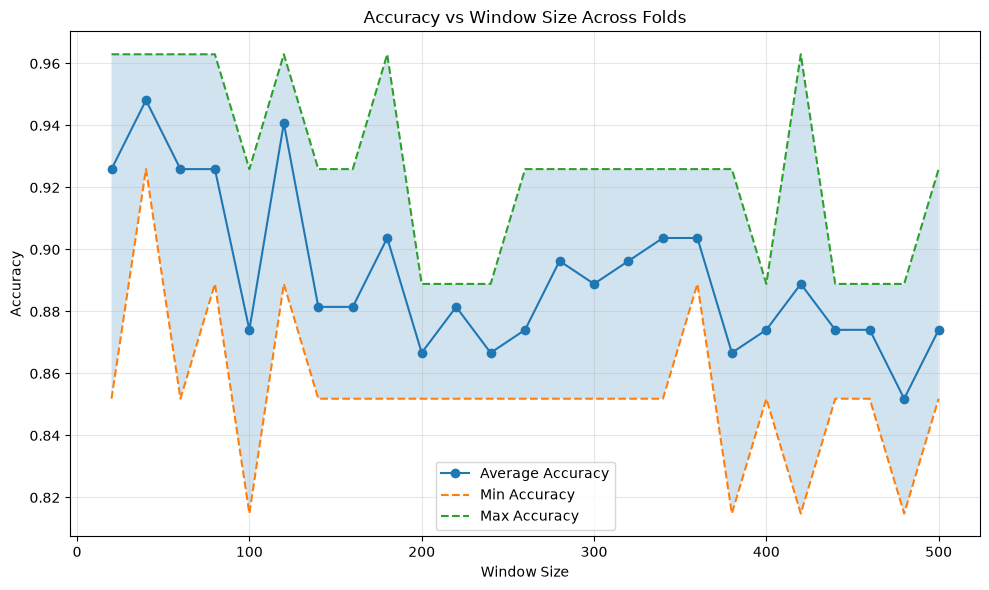

In [46]:
accuracy_summary = (
    metrics_df
    .groupby("window_size")["accuracy"]
    .agg(
        avg_accuracy="mean",
        min_accuracy="min",
        max_accuracy="max"
    )
    .reset_index()
    .sort_values("window_size")
)

plt.figure(figsize=(10, 6))

# Average accuracy
plt.plot(
    accuracy_summary["window_size"],
    accuracy_summary["avg_accuracy"],
    marker="o",
    label="Average Accuracy"
)

# Min / Max accuracy
plt.plot(
    accuracy_summary["window_size"],
    accuracy_summary["min_accuracy"],
    linestyle="--",
    label="Min Accuracy"
)

plt.plot(
    accuracy_summary["window_size"],
    accuracy_summary["max_accuracy"],
    linestyle="--",
    label="Max Accuracy"
)

# Shade the min-max range
plt.fill_between(
    accuracy_summary["window_size"],
    accuracy_summary["min_accuracy"],
    accuracy_summary["max_accuracy"],
    alpha=0.2
)

plt.xlabel("Window Size")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Window Size Across Folds")

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [47]:
accuracy_summary.sort_values(by=["avg_accuracy", "window_size"], ascending=[False, True]).head(10)

,window_size,avg_accuracy,min_accuracy,max_accuracy
1,40,0.948148,0.925926,0.962963
5,120,0.940741,0.888889,0.962963
0,20,0.925926,0.851852,0.962963
2,60,0.925926,0.851852,0.962963
3,80,0.925926,0.888889,0.962963
8,180,0.903704,0.851852,0.962963
16,340,0.903704,0.851852,0.925926
17,360,0.903704,0.888889,0.925926
13,280,0.896296,0.851852,0.925926
15,320,0.896296,0.851852,0.925926


In [48]:
EXAMINING_WINDOW_SIZE = accuracy_summary.sort_values(
    by=["avg_accuracy", "window_size"],
    ascending=[False, True]
).iloc[0]["window_size"]
EXAMINING_WINDOW_SIZE

np.float64(40.0)

In [49]:
metrics_df[metrics_df["window_size"] == EXAMINING_WINDOW_SIZE]
# metrics_df[metrics_df["window_size"] == 100]

,accuracy,iot_device_count,non_iot_device_count,false_positive_count,false_negative_count,false_positive,false_negative,fold,window_size
5,0.925926,21,6,2,0,"[ac:bc:32:d4:6f:2f, b4:ce:f6:a7:a3:c2]",[],0,40
6,0.925926,21,6,1,1,[b4:ce:f6:a7:a3:c2],[74:6a:89:00:2e:25],1,40
7,0.962963,21,6,1,0,[b4:ce:f6:a7:a3:c2],[],2,40
8,0.962963,21,6,1,0,[74:2f:68:81:69:42],[],3,40
9,0.962963,21,6,0,1,[],[74:6a:89:00:2e:25],4,40


In [50]:
detail_metrics_df[(detail_metrics_df["window_size"] == EXAMINING_WINDOW_SIZE) & (detail_metrics_df["aggregated_prediction"] != detail_metrics_df["is_iot_device"])]

,eth.src,total_predictions,prediction_0,prediction_1,aggregated_prediction,is_iot_device,device_type,vendor,fold,window_size
18,ac:bc:32:d4:6f:2f,230,113,117,1,0,NaN,NaN,0,40
19,b4:ce:f6:a7:a3:c2,98,49,49,1,0,NaN,NaN,0,40
16,74:6a:89:00:2e:25,1,1,0,0,1,blood pressure monitor,Blipcare,1,40
19,b4:ce:f6:a7:a3:c2,2,1,1,1,0,NaN,NaN,1,40
19,b4:ce:f6:a7:a3:c2,100,47,53,1,0,NaN,NaN,2,40
15,74:2f:68:81:69:42,285,119,166,1,0,NaN,NaN,3,40
16,74:6a:89:00:2e:25,1,1,0,0,1,blood pressure monitor,Blipcare,4,40


In [51]:
detail_metrics_df[(detail_metrics_df["window_size"] == EXAMINING_WINDOW_SIZE) & (detail_metrics_df["fold"] == 3)]

,eth.src,total_predictions,prediction_0,prediction_1,aggregated_prediction,is_iot_device,device_type,vendor,fold,window_size
0,00:16:6c:ab:6b:88,2160,4,2156,1,1,camera,Samsung,3,40
1,00:24:e4:11:18:a8,2159,40,2119,1,1,baby monitor,Withings,3,40
2,00:24:e4:1b:6f:96,3,0,3,1,1,smart scale,Withings,3,40
3,00:24:e4:20:28:c6,2160,6,2154,1,1,sleep sensor,Withings,3,40
4,00:62:6e:51:27:2e,2160,21,2139,1,1,camera,Insteon,3,40
5,08:21:ef:3b:fc:e3,382,311,71,0,0,NaN,NaN,3,40
6,18:b4:30:25:be:e4,2,0,2,1,1,smoke alarm,Nest,3,40
7,18:b7:9e:02:20:44,1640,678,962,1,1,smart speaker,Invoxia,3,40
8,30:8c:fb:2f:e4:b2,2160,24,2136,1,1,camera,Dropcam,3,40
9,40:f3:08:ff:1e:da,176,102,74,0,0,NaN,NaN,3,40


- Out of the folds that achieve the best accuracy, these four devices are usually misclassified `[00:24:e4:1b:6f:96, 18:b4:30:25:be:e4, 74:6a:89:00:2e:25]`

In [52]:
misclassfied_devices = ["08:21:ef:3b:fc:e3", "b4:ce:f6:a7:a3:c2","40:f3:08:ff:1e:da", "d0:a6:37:df:a1:e1"]
for mac in misclassfied_devices:
    print(f"mac: {mac}, device_name: {device_dict_1[mac]["device_name"]}, is_iot_device: {device_dict_1[mac]["is_iot_device"]}, vendor: {device_dict_1[mac]["vendor"]}")

mac: 08:21:ef:3b:fc:e3, device_name: Samsung Galaxy Tab, is_iot_device: 0, vendor: nan
mac: b4:ce:f6:a7:a3:c2, device_name: Android Phone, is_iot_device: 0, vendor: nan
mac: 40:f3:08:ff:1e:da, device_name: Android Phone, is_iot_device: 0, vendor: nan
mac: d0:a6:37:df:a1:e1, device_name: IPhone, is_iot_device: 0, vendor: nan


In [53]:
features_window_EXAMINING_WINDOW_SIZE = build_feature(raw_df=process_df, device_to_be_include=device_to_be_include, window=EXAMINING_WINDOW_SIZE)
data_df_EXAMINING_WINDOW_SIZE = label_features(features=features_window_EXAMINING_WINDOW_SIZE, device_mapping=device_dict_1)
training_and_validation_folds_EXAMINING_WINDOW_SIZE = device_capture_repeated_split(
    df=data_df_EXAMINING_WINDOW_SIZE,
    list_of_devices_to_be_classified=list_of_devices_to_be_classified,
    n_splits=KPLITS,
    random_state=RANDOM_STATE
)

- Examining the errors

In [54]:
TARGET_DEVICES = misclassfied_devices


def fit_current_model(
    train_df,
    val_df,
    feature_columns,
    random_state=RANDOM_STATE,
):
    """Fit the same undersampling + scaling + decision-tree pipeline."""
    X_train = train_df[feature_columns]
    y_train = train_df[LABEL_COLUMN]
    X_val = val_df[feature_columns]

    sampler = create_under_sampler(random_seed=random_state)
    X_train_resampled, y_train_resampled = sampler.fit_resample(
        X_train,
        y_train,
    )

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_resampled)
    X_val_scaled = scaler.transform(X_val)

    model = create_decision_tree(random_seed=random_state)
    model.fit(X_train_scaled, y_train_resampled)

    predictions = model.predict(X_val_scaled)
    positive_class_index = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_val_scaled)[:, positive_class_index]

    return predictions, probabilities, model, scaler


def run_fold_predictions(
    data,
    folds,
    feature_columns,
):
    prediction_parts = []
    fitted_objects = []

    for fold in folds:
        fold_number = fold["fold"]

        train_df = data.iloc[fold["train_iloc"]].copy()
        val_df = data.iloc[fold["val_iloc"]].copy()

        predictions, probabilities, model, scaler = fit_current_model(
            train_df=train_df,
            val_df=val_df,
            feature_columns=feature_columns,
        )

        val_df["fold"] = fold_number
        val_df["prediction_each_window"] = predictions
        val_df["iot_probability"] = probabilities
        val_df["is_active"] = val_df[feature_columns].sum(axis=1) > 0
        val_df["is_correct"] = (
            val_df["prediction_each_window"] == val_df[LABEL_COLUMN]
        )

        prediction_parts.append(val_df)

        fitted_objects.append(
            {
                "fold": fold_number,
                "model": model,
                "scaler": scaler,
                "train_df": train_df,
            }
        )

    return (
        pd.concat(prediction_parts, ignore_index=True),
        fitted_objects,
    )


predictions_EXAMINING_WINDOW_SIZE, fitted_models_EXAMINING_WINDOW_SIZE = run_fold_predictions(
    data=data_df_EXAMINING_WINDOW_SIZE,
    folds=training_and_validation_folds_EXAMINING_WINDOW_SIZE,
    feature_columns=FEATURE_COLUMNS,
)

predictions_EXAMINING_WINDOW_SIZE.head()

,capture_id,window,eth.src,packet_count,total_bytes,is_iot_device,device_type,vendor,fold,prediction_each_window,iot_probability,is_active,is_correct
0,16-09-23,624,00:24:e4:1b:6f:96,78,25846,1,smart scale,Withings,0,0,0.0,True,False
1,16-09-23,625,00:24:e4:1b:6f:96,33,9280,1,smart scale,Withings,0,1,1.0,True,True
2,16-09-23,1121,b4:ce:f6:a7:a3:c2,17,3306,0,NaN,NaN,0,0,0.0,True,True
3,16-09-23,1122,b4:ce:f6:a7:a3:c2,200,29070,0,NaN,NaN,0,0,0.0,True,True
4,16-09-23,1123,b4:ce:f6:a7:a3:c2,182,43440,0,NaN,NaN,0,1,1.0,True,False


In [55]:
active_inactive_diagnostic = (
    predictions_EXAMINING_WINDOW_SIZE[
        predictions_EXAMINING_WINDOW_SIZE["eth.src"].isin(TARGET_DEVICES)
    ]
    .groupby(
        [
            "fold",
            "eth.src",
            "capture_id",
            LABEL_COLUMN,
            "is_active",
        ],
        observed=True,
        as_index=False,
    )
    .agg(
        windows=("prediction_each_window", "size"),
        predicted_iot=("prediction_each_window", "sum"),
        predicted_iot_rate=("prediction_each_window", "mean"),
        mean_iot_probability=("iot_probability", "mean"),
        accuracy=("is_correct", "mean"),
        packet_count=("packet_count", "sum"),
        total_bytes=("total_bytes", "sum"),
    )
)

active_inactive_diagnostic["device_name"] = (
    active_inactive_diagnostic["eth.src"]
    .map(lambda mac: device_dict_1[mac]["device_name"])
)

In [56]:
active_inactive_diagnostic[
    [
        "fold",
        "eth.src",
        "device_name",
        "capture_id",
        "is_active",
        "windows",
        "predicted_iot",
        "predicted_iot_rate",
        "mean_iot_probability",
        "accuracy",
    ]
].sort_values(
    ["is_active", "eth.src", "fold"]
)

,fold,eth.src,device_name,capture_id,is_active,windows,predicted_iot,predicted_iot_rate,mean_iot_probability,accuracy
0,0,08:21:ef:3b:fc:e3,Samsung Galaxy Tab,16-09-27,True,622,53,0.085209,0.175367,0.914791
4,1,08:21:ef:3b:fc:e3,Samsung Galaxy Tab,16-09-23,True,1467,218,0.148603,0.193616,0.851397
8,2,08:21:ef:3b:fc:e3,Samsung Galaxy Tab,16-10-04,True,736,81,0.110054,0.141437,0.889946
12,3,08:21:ef:3b:fc:e3,Samsung Galaxy Tab,16-09-29,True,382,36,0.094241,0.137572,0.905759
16,4,08:21:ef:3b:fc:e3,Samsung Galaxy Tab,16-10-03,True,657,70,0.106545,0.134398,0.893455
1,0,40:f3:08:ff:1e:da,Android Phone,16-09-29,True,110,21,0.190909,0.239204,0.809091
5,1,40:f3:08:ff:1e:da,Android Phone,16-10-07,True,176,41,0.232955,0.253913,0.767045
9,2,40:f3:08:ff:1e:da,Android Phone,16-09-29,True,110,17,0.154545,0.192756,0.845455
13,3,40:f3:08:ff:1e:da,Android Phone,16-10-07,True,176,41,0.232955,0.258003,0.767045
17,4,40:f3:08:ff:1e:da,Android Phone,16-09-29,True,110,19,0.172727,0.222874,0.827273


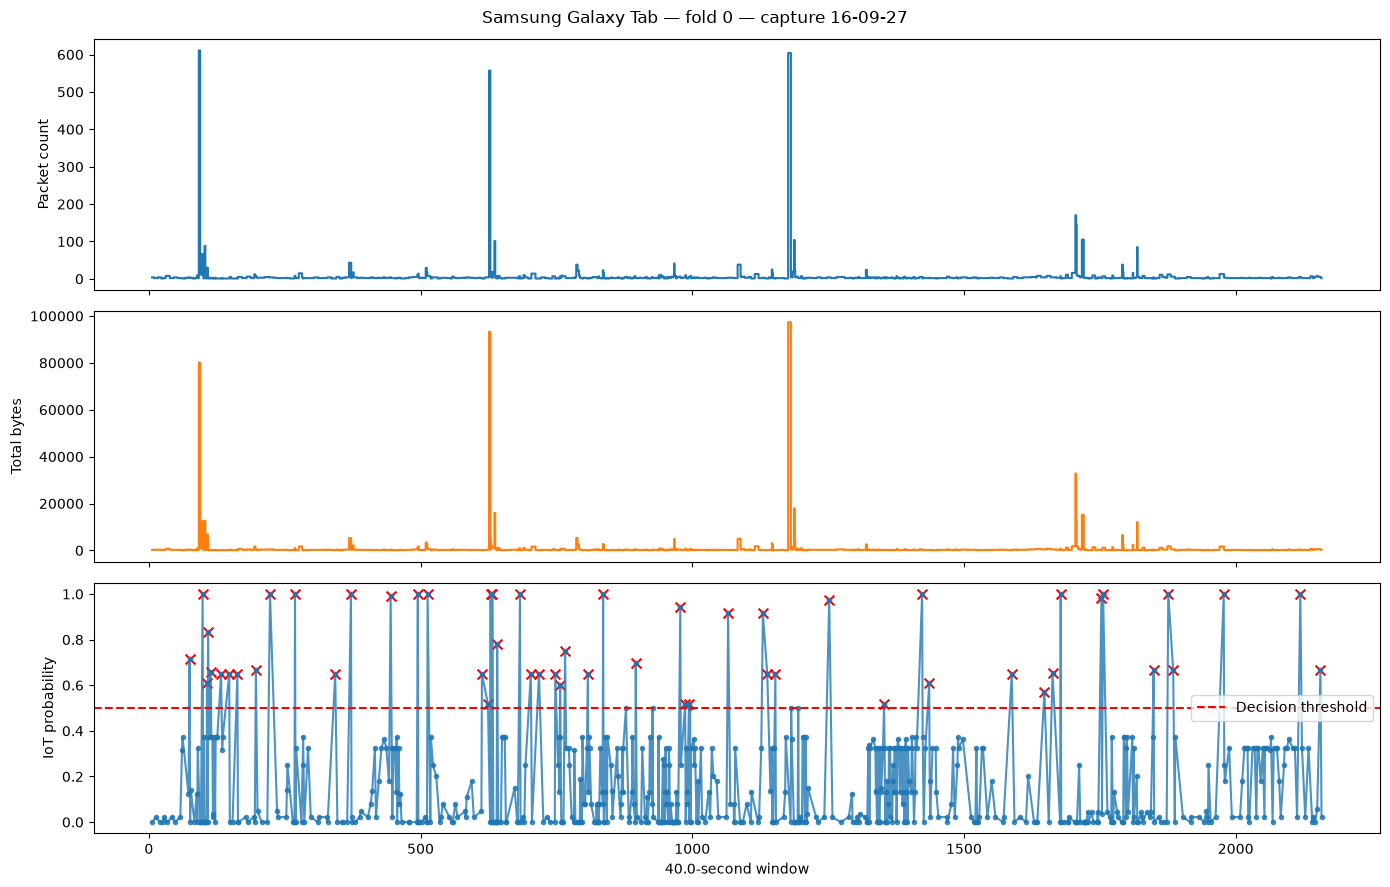

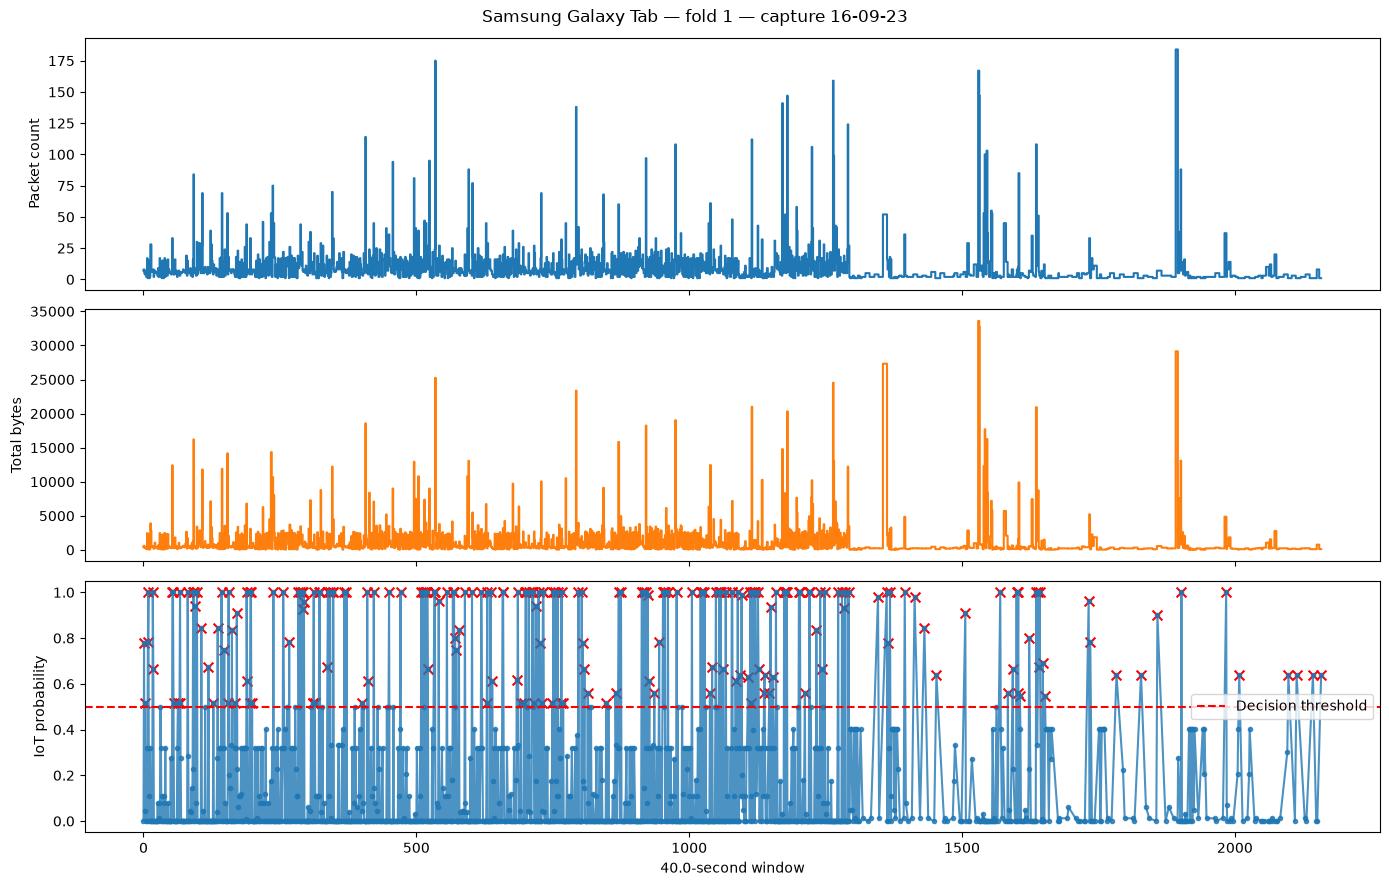

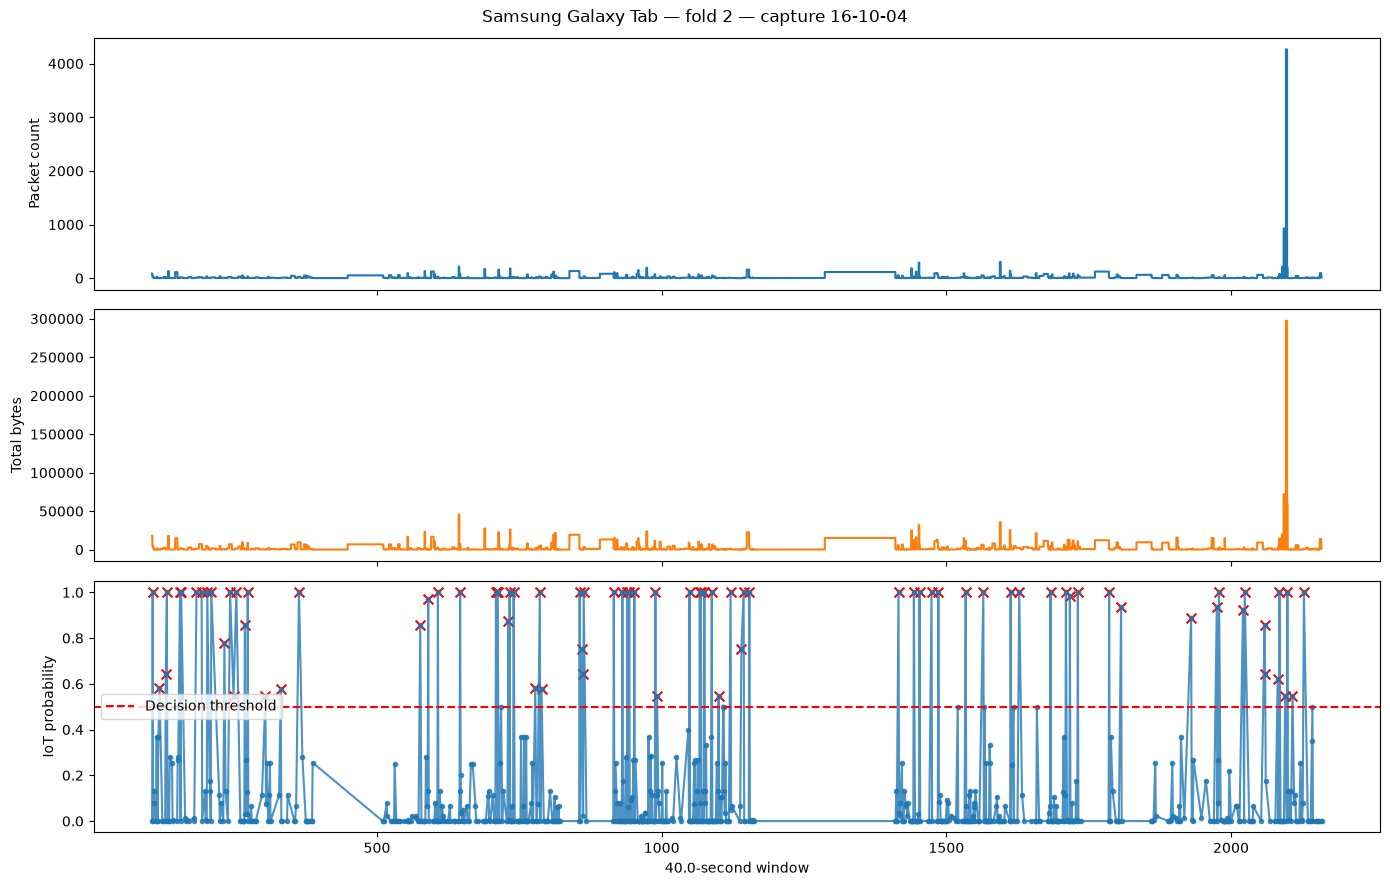

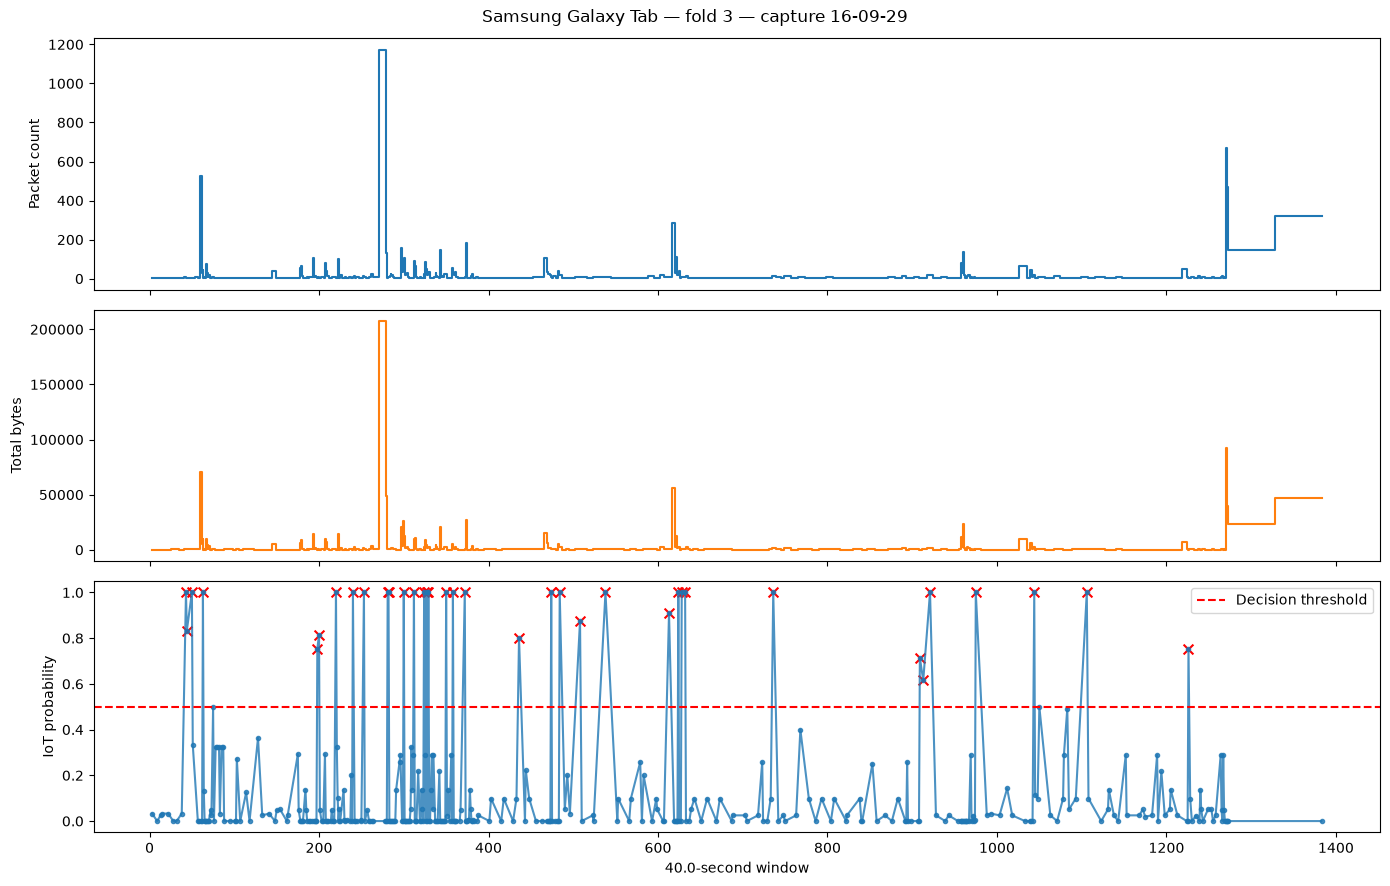

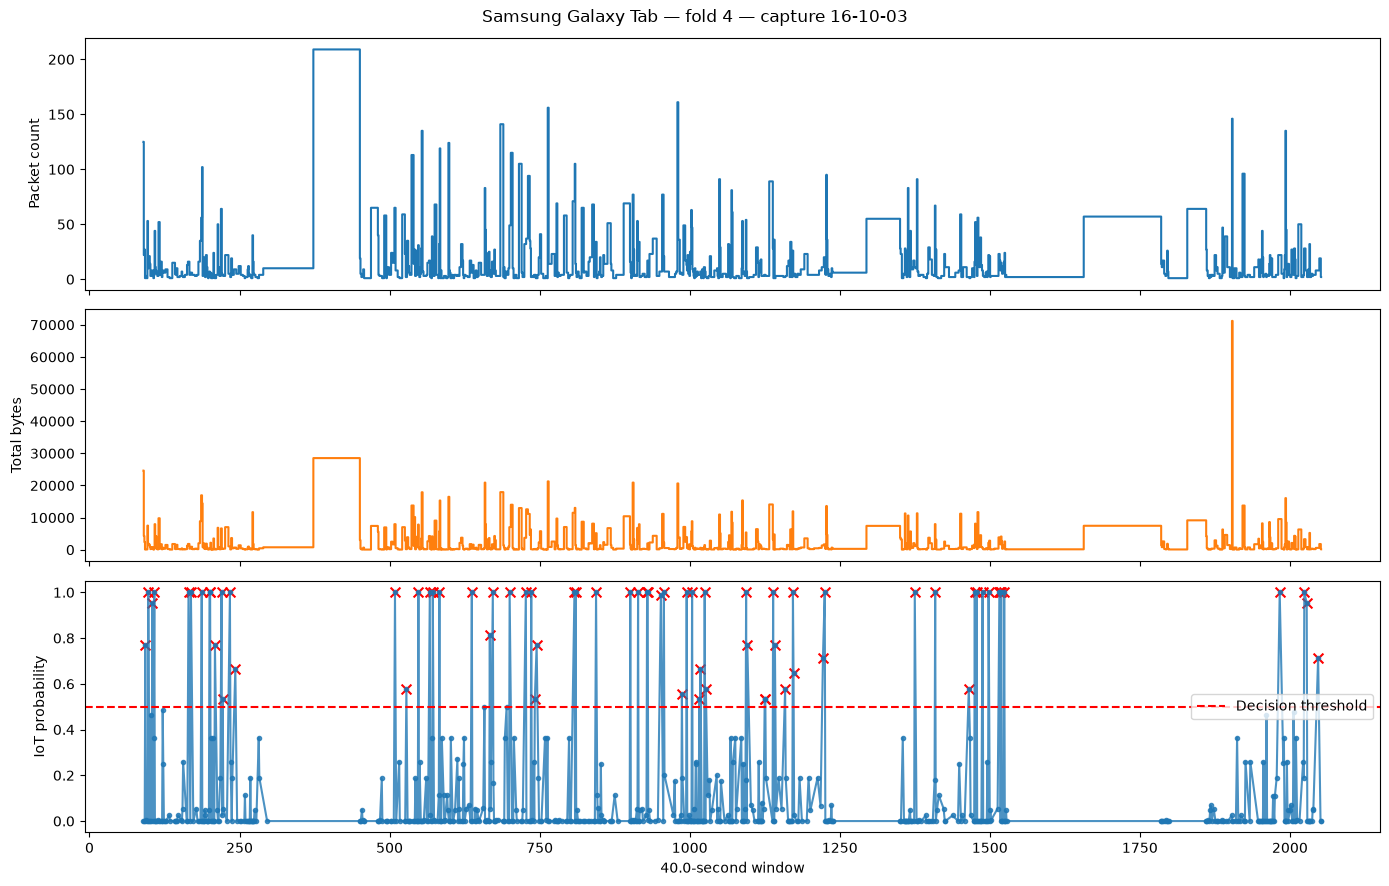

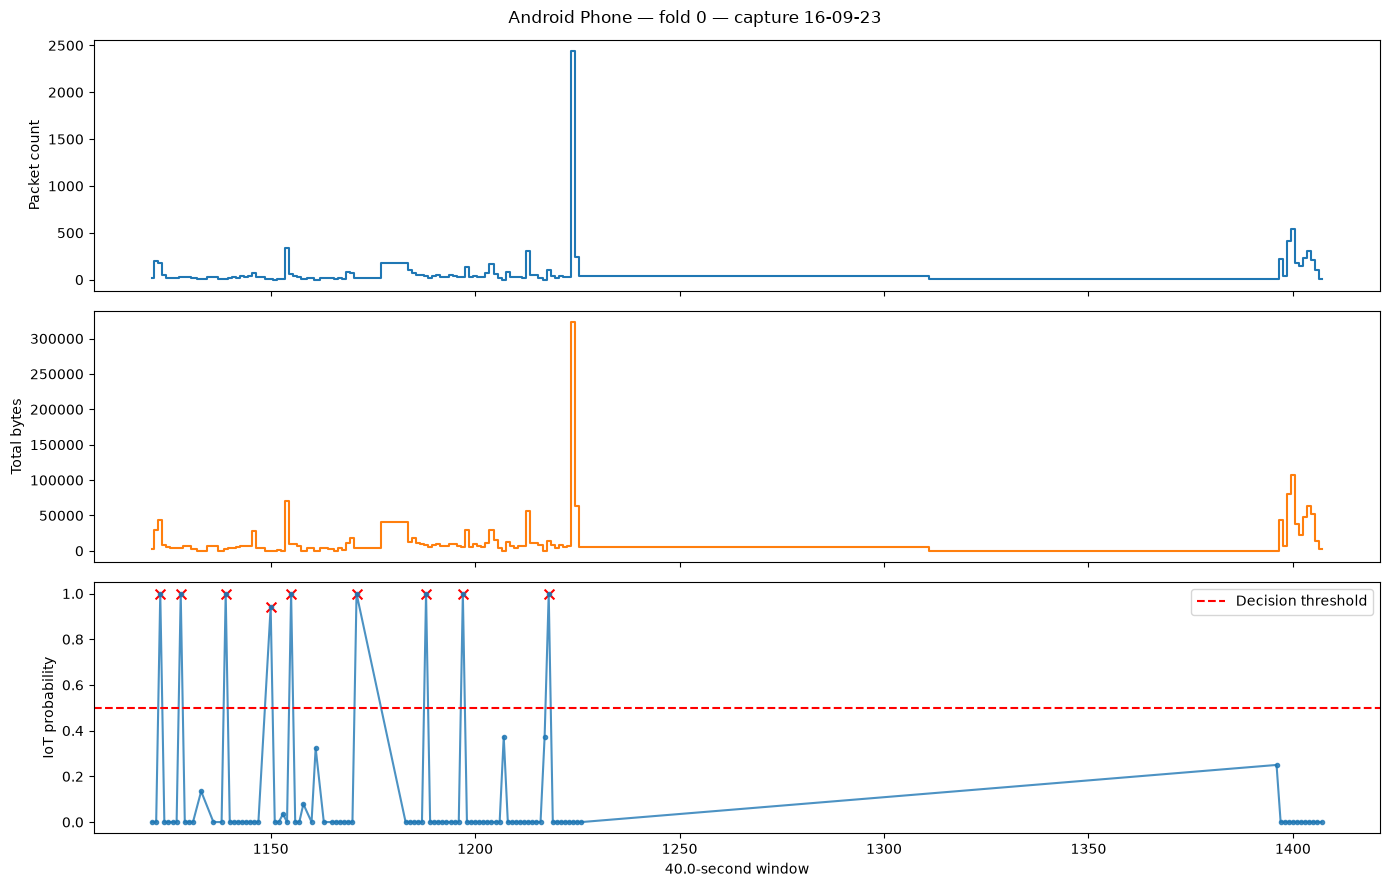

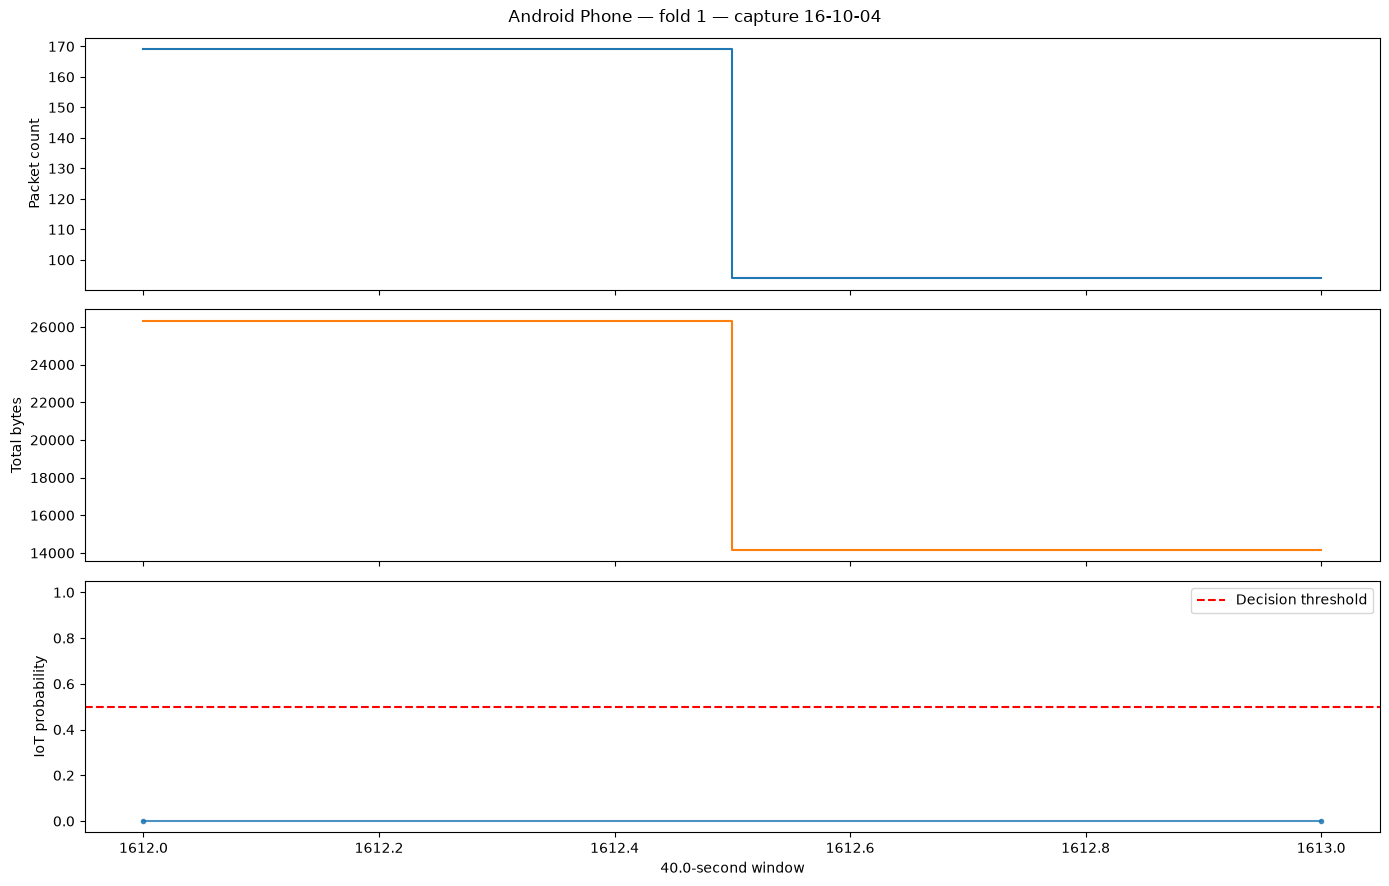

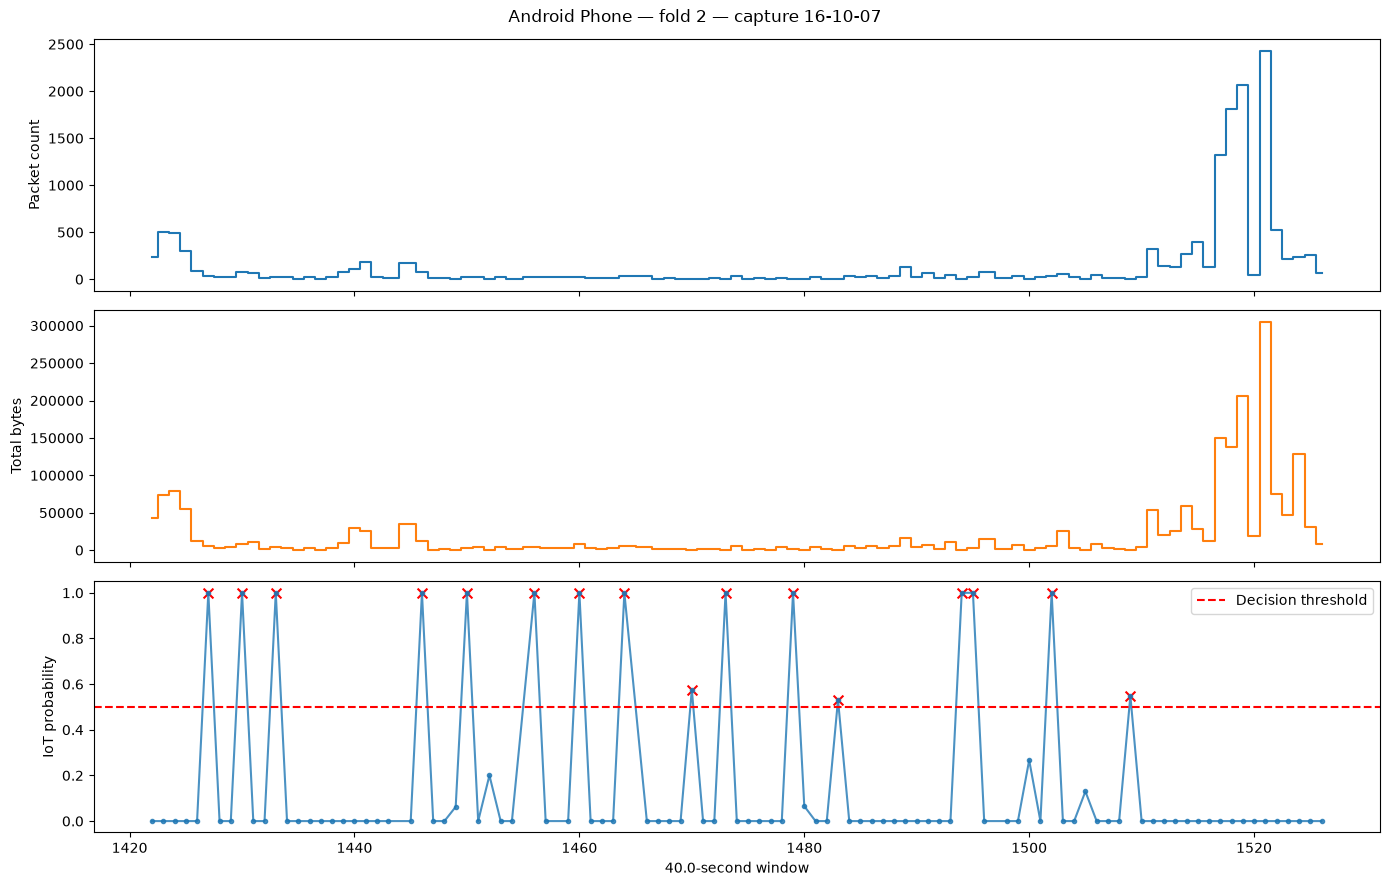

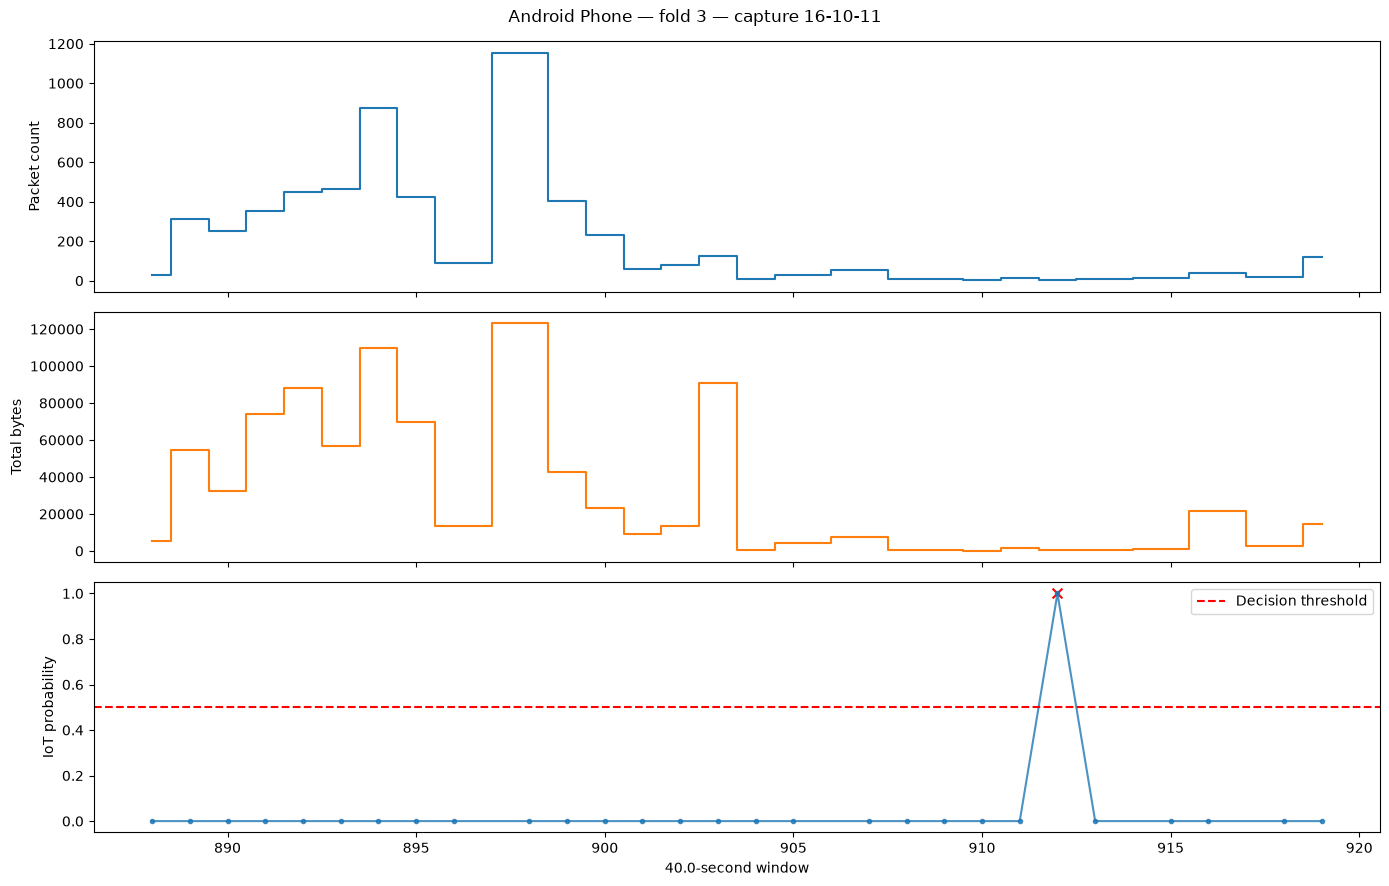

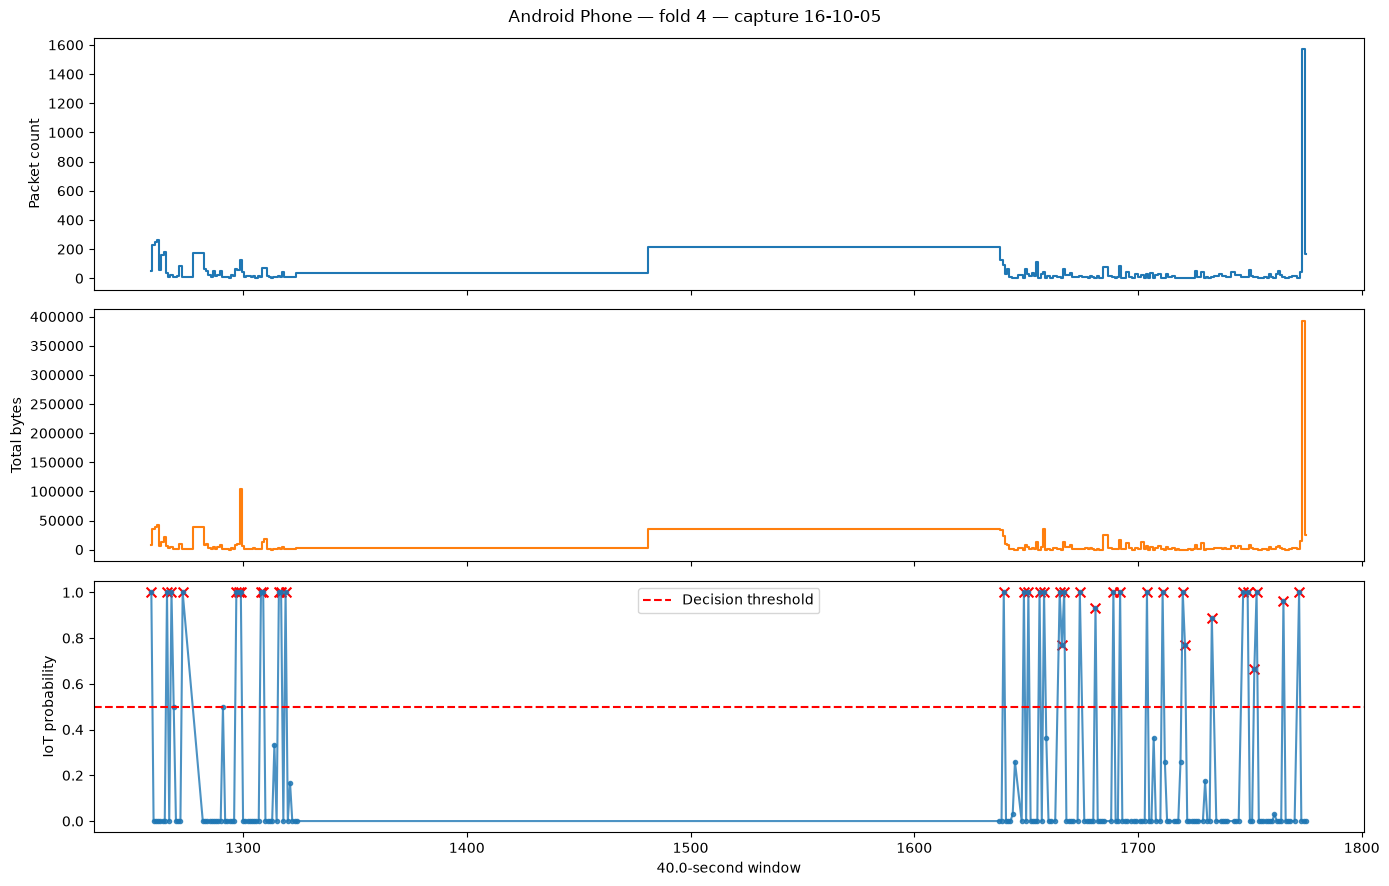

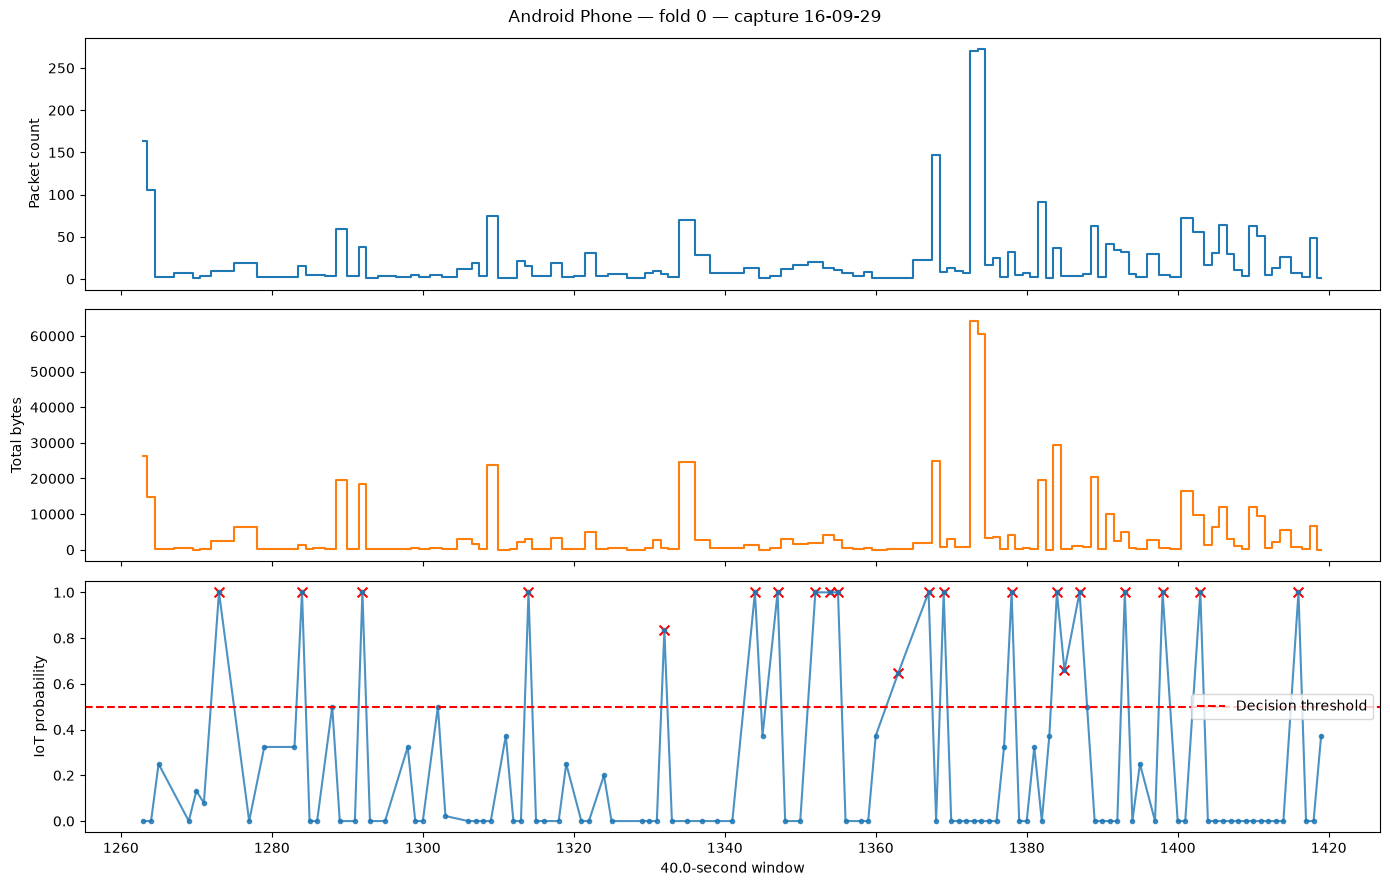

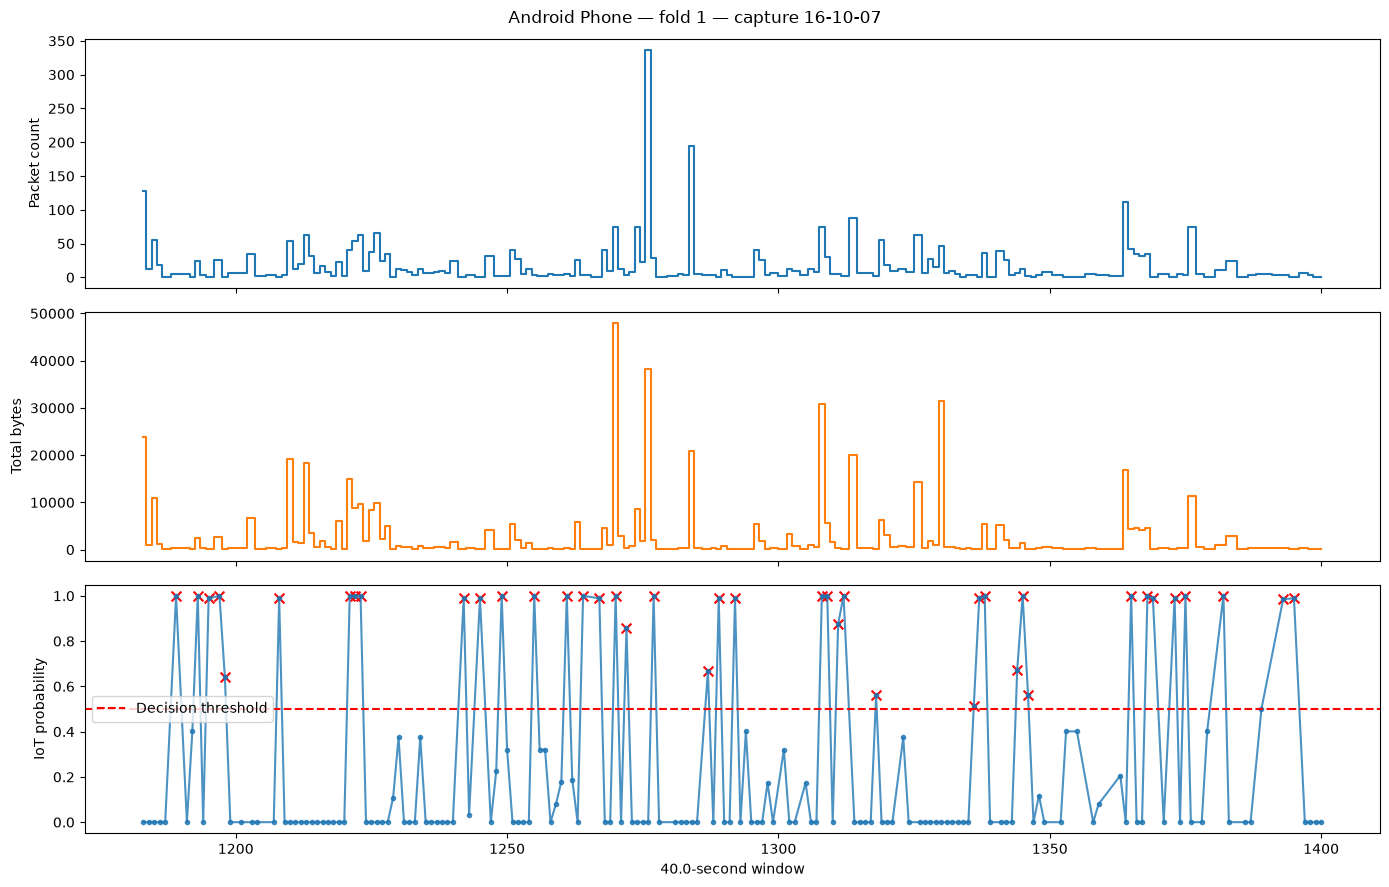

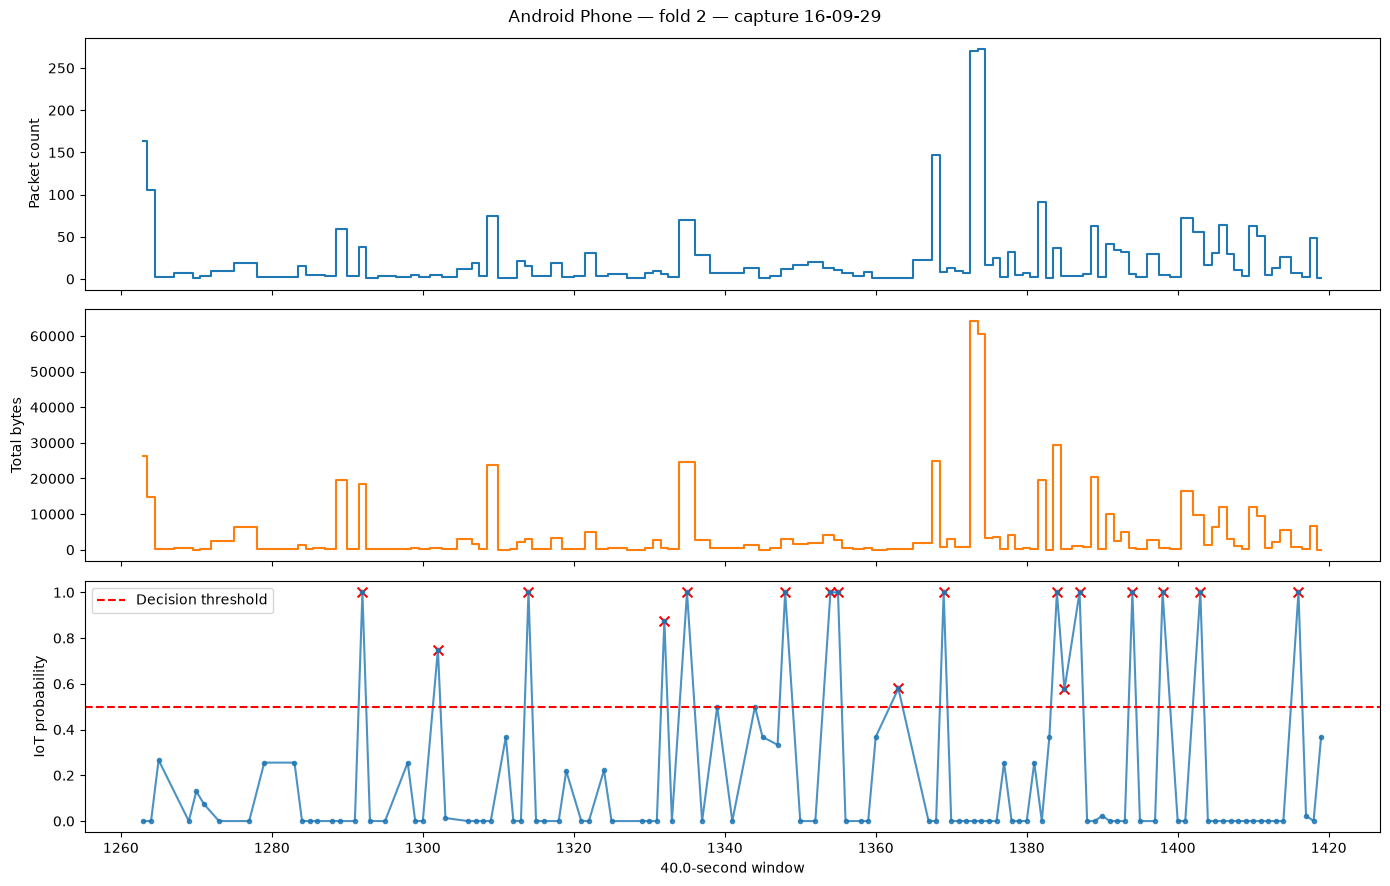

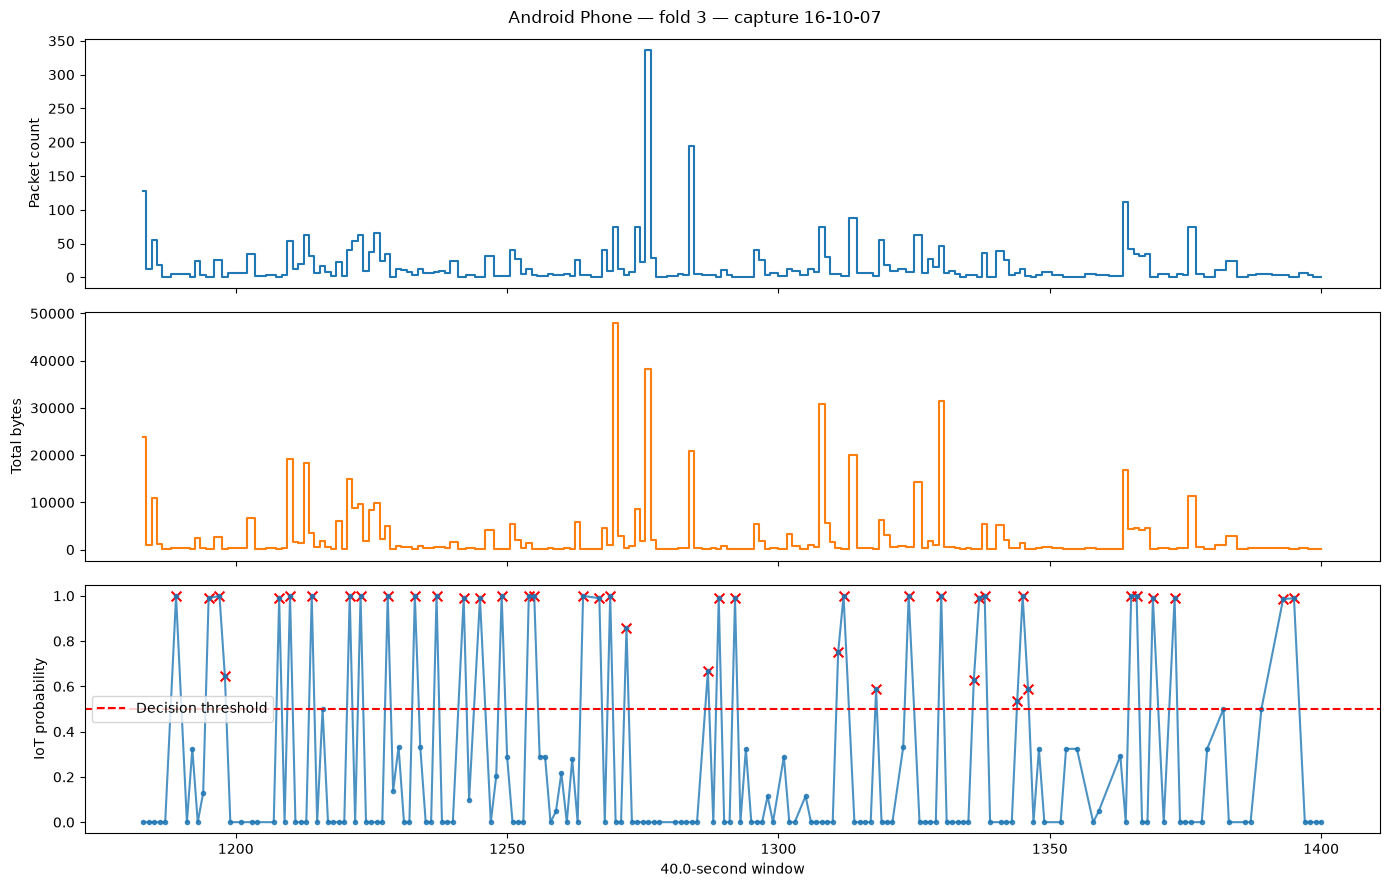

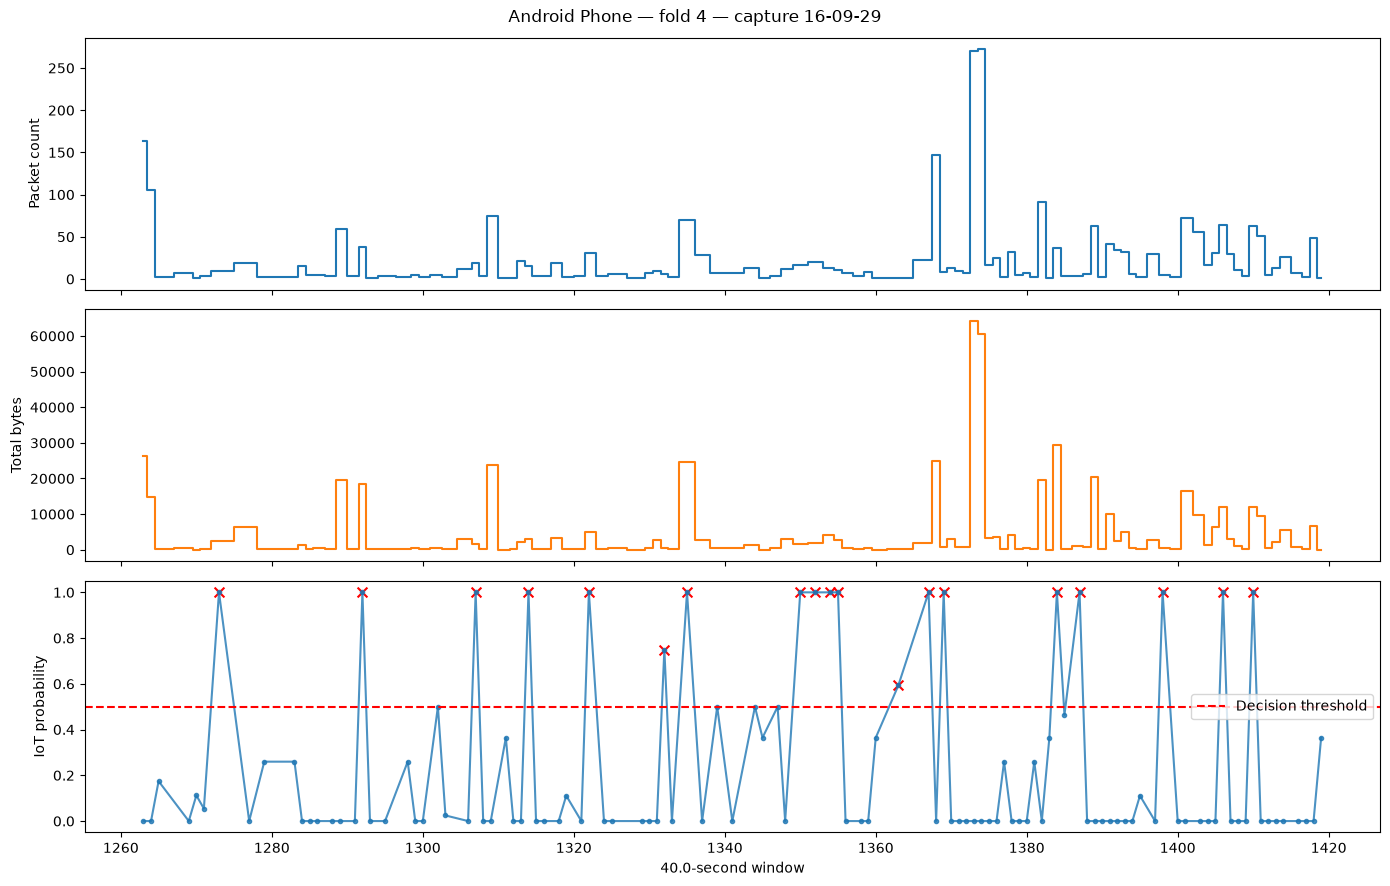

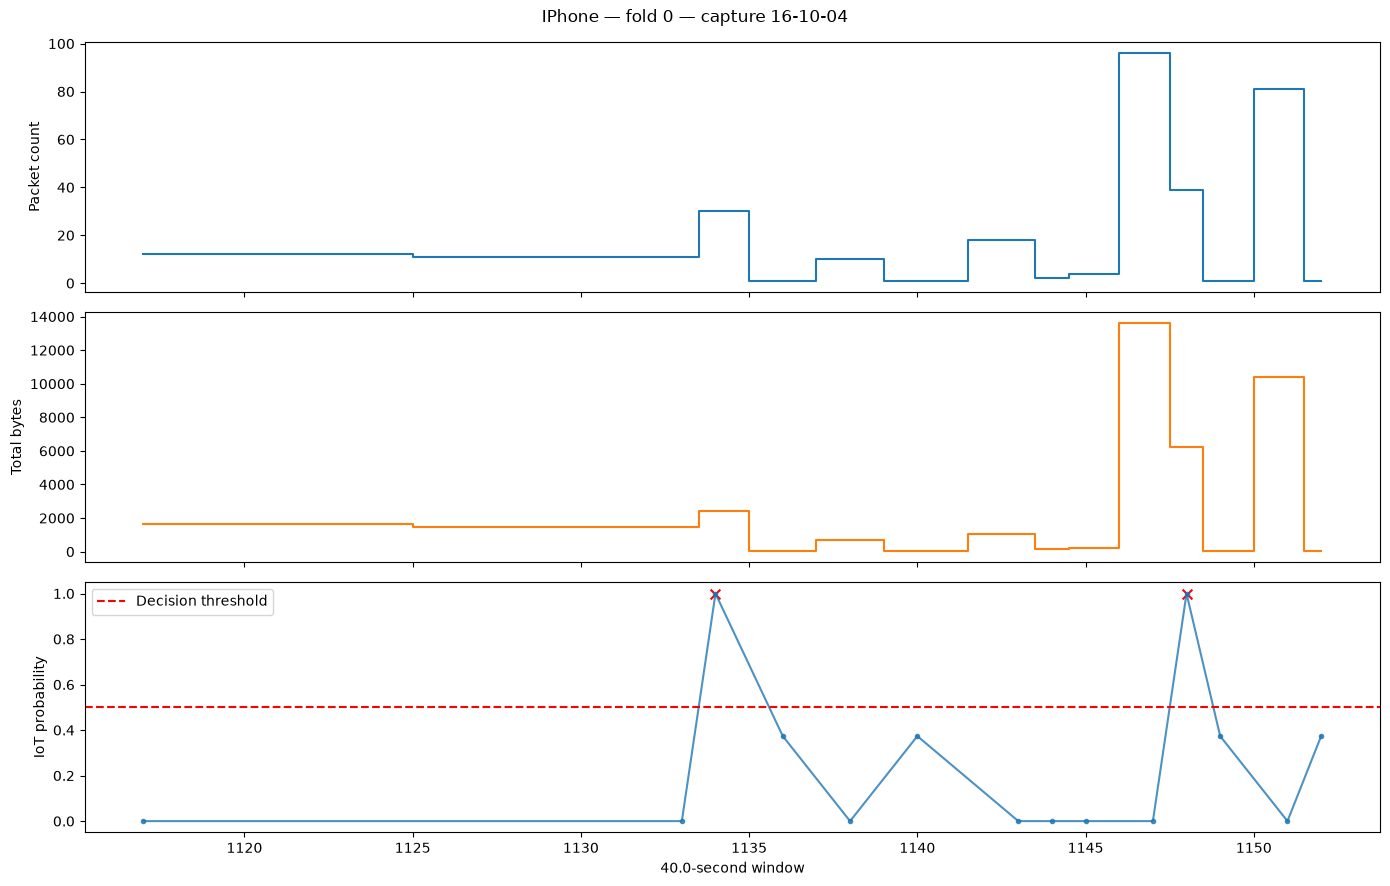

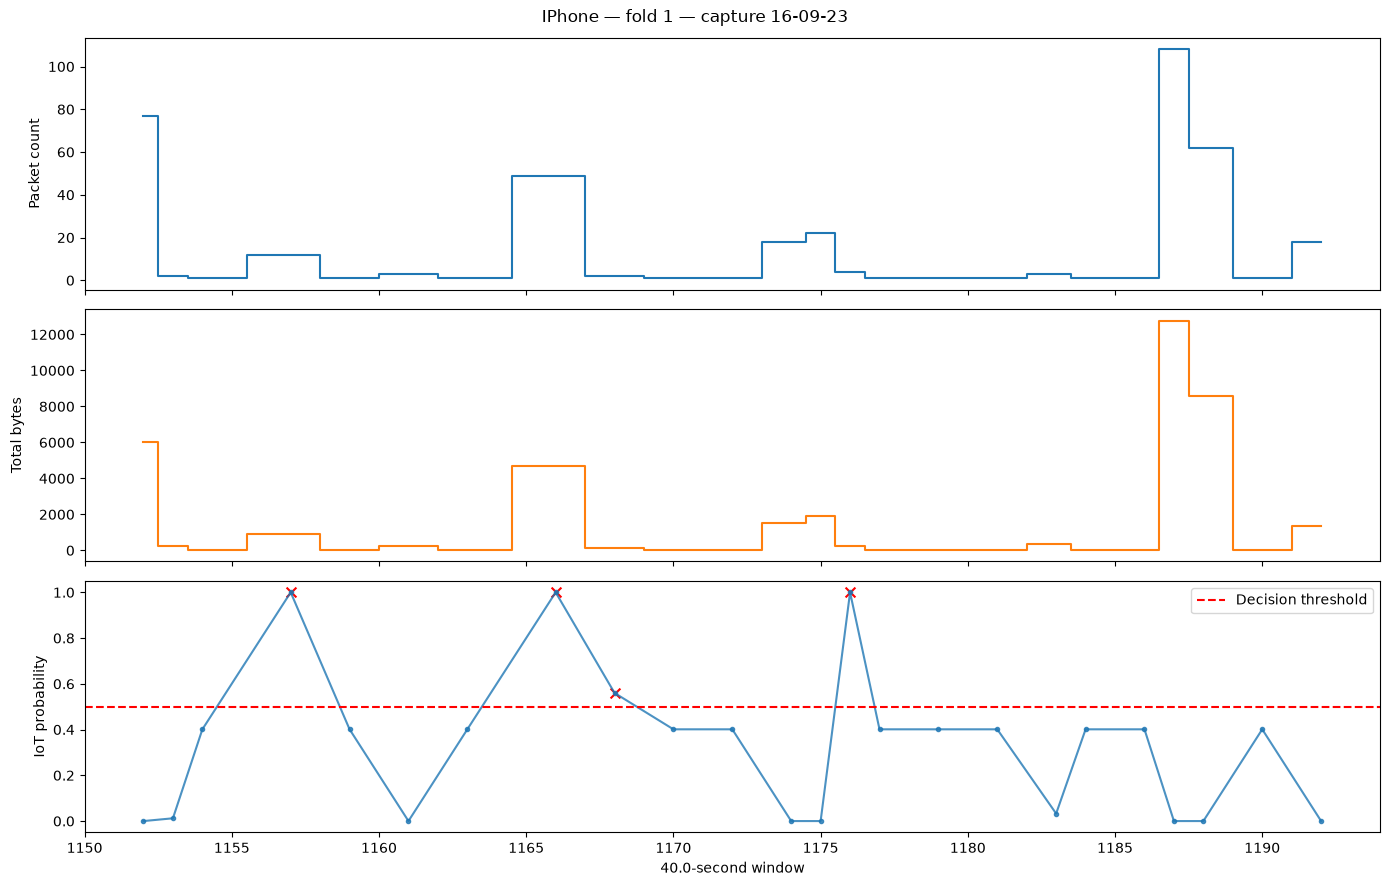

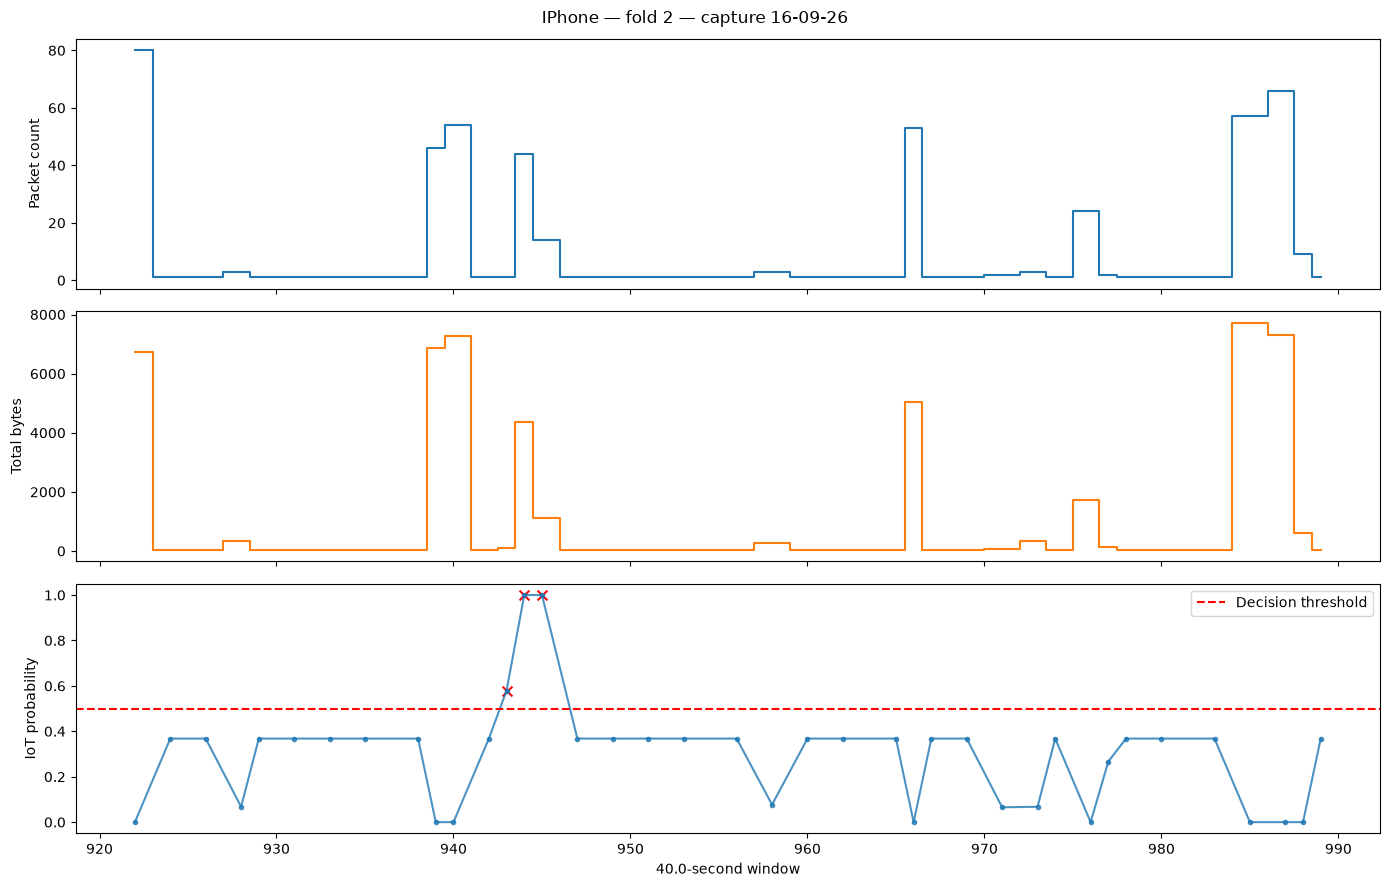

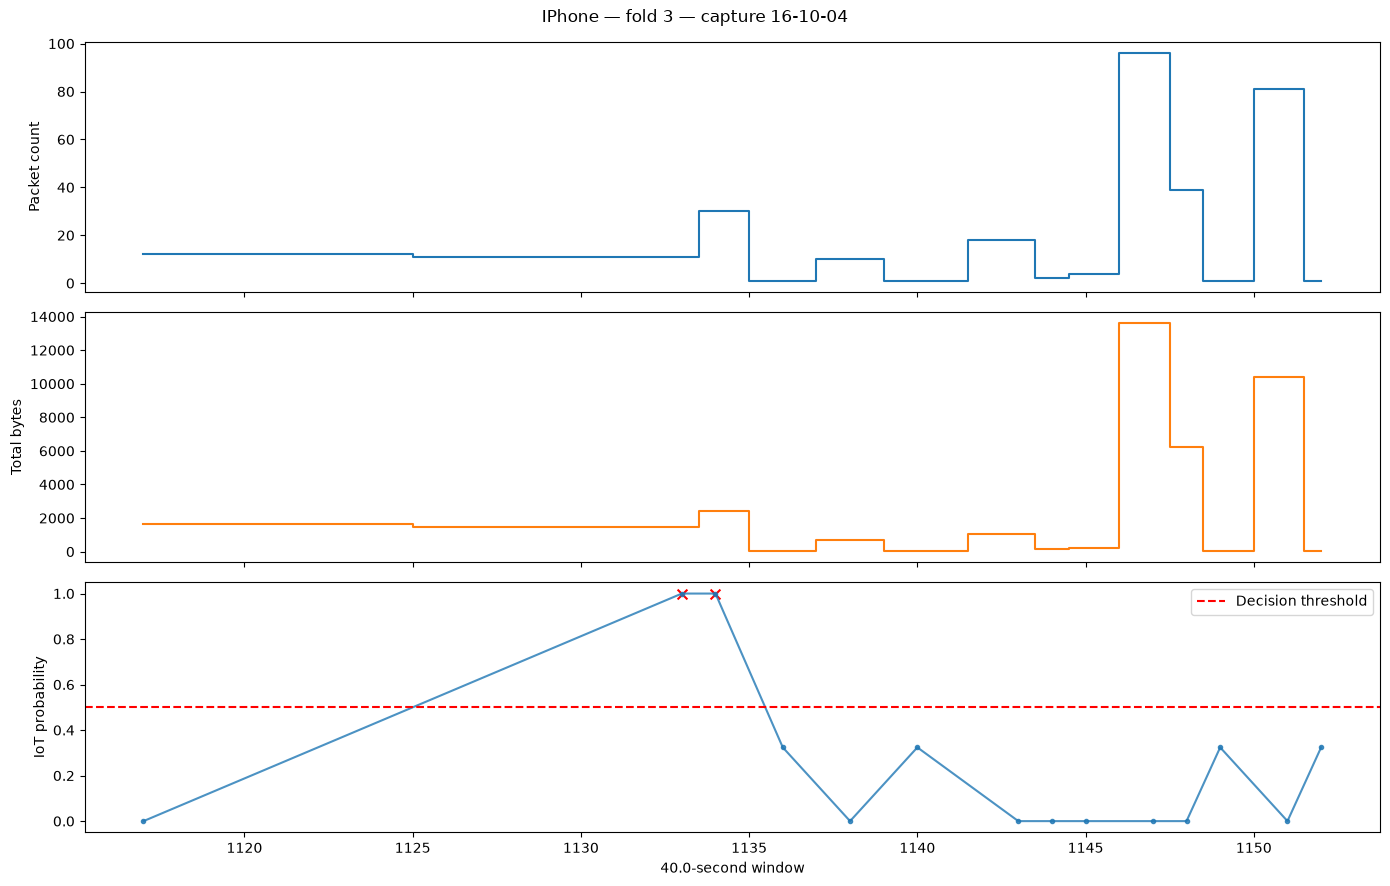

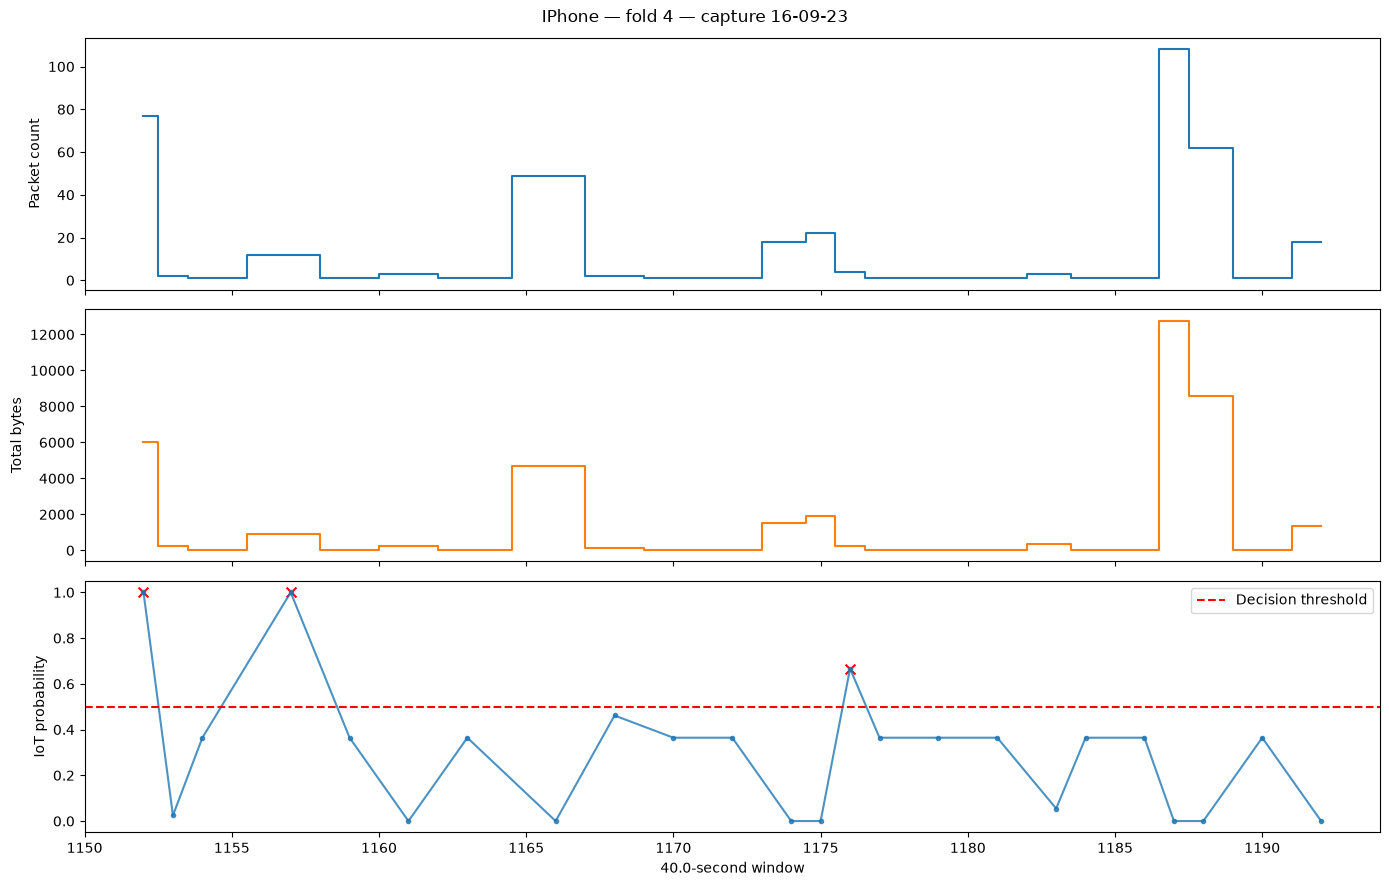

In [57]:
def plot_device_timeline(
    prediction_df,
    mac,
    fold_number=0,
):
    device_df = (
        prediction_df[
            (prediction_df["eth.src"] == mac)
            & (prediction_df["fold"] == fold_number)
        ]
        .sort_values("window")
        .copy()
    )

    if device_df.empty:
        print(f"No observations for {mac} in fold {fold_number}")
        return

    device_name = device_dict_1[mac]["device_name"]
    capture_ids = device_df["capture_id"].unique()

    fig, axes = plt.subplots(
        3,
        1,
        figsize=(14, 9),
        sharex=True,
    )

    axes[0].step(
        device_df["window"],
        device_df["packet_count"],
        where="mid",
    )
    axes[0].set_ylabel("Packet count")

    axes[1].step(
        device_df["window"],
        device_df["total_bytes"],
        where="mid",
        color="tab:orange",
    )
    axes[1].set_ylabel("Total bytes")

    axes[2].plot(
        device_df["window"],
        device_df["iot_probability"],
        marker=".",
        linestyle="-",
        alpha=0.8,
    )
    axes[2].axhline(
        0.5,
        color="red",
        linestyle="--",
        label="Decision threshold",
    )
    axes[2].set_ylabel("IoT probability")
    axes[2].set_xlabel(f"{EXAMINING_WINDOW_SIZE}-second window")
    axes[2].set_ylim(-0.05, 1.05)
    axes[2].legend()

    incorrect = device_df[~device_df["is_correct"]]

    axes[2].scatter(
        incorrect["window"],
        incorrect["iot_probability"],
        color="red",
        marker="x",
        s=50,
        label="Incorrect",
    )

    fig.suptitle(
        f"{device_name} — fold {fold_number} — "
        f"capture {', '.join(map(str, capture_ids))}"
    )
    plt.tight_layout()
    plt.show()


for device_mac in TARGET_DEVICES:
    for fold_num in range(KPLITS):
        plot_device_timeline(
            predictions_EXAMINING_WINDOW_SIZE,
            mac=device_mac,
            fold_number=fold_num,
        )

In [58]:
activity_boundaries = (
    predictions_EXAMINING_WINDOW_SIZE[
        predictions_EXAMINING_WINDOW_SIZE["is_active"]
        & predictions_EXAMINING_WINDOW_SIZE["eth.src"].isin(TARGET_DEVICES)
    ]
    .groupby(
        ["fold", "eth.src", "capture_id"],
        observed=True,
        as_index=False,
    )
    .agg(
        first_active_window=("window", "min"),
        last_active_window=("window", "max"),
        active_windows=("window", "size"),
    )
)

activity_boundaries["first_active_second"] = (
    activity_boundaries["first_active_window"] * EXAMINING_WINDOW_SIZE
)

activity_boundaries["last_active_second"] = (
    activity_boundaries["last_active_window"] * EXAMINING_WINDOW_SIZE
)

activity_boundaries

,fold,eth.src,capture_id,first_active_window,last_active_window,active_windows,first_active_second,last_active_second
0,0,08:21:ef:3b:fc:e3,16-09-27,6,2158,622,240.0,86320.0
1,0,40:f3:08:ff:1e:da,16-09-29,1263,1419,110,50520.0,56760.0
2,0,b4:ce:f6:a7:a3:c2,16-09-23,1121,1407,98,44840.0,56280.0
3,0,d0:a6:37:df:a1:e1,16-10-04,1117,1152,14,44680.0,46080.0
4,1,08:21:ef:3b:fc:e3,16-09-23,0,2158,1467,0.0,86320.0
5,1,40:f3:08:ff:1e:da,16-10-07,1183,1400,176,47320.0,56000.0
6,1,b4:ce:f6:a7:a3:c2,16-10-04,1612,1613,2,64480.0,64520.0
7,1,d0:a6:37:df:a1:e1,16-09-23,1152,1192,24,46080.0,47680.0
8,2,08:21:ef:3b:fc:e3,16-10-04,105,2159,736,4200.0,86360.0
9,2,40:f3:08:ff:1e:da,16-09-29,1263,1419,110,50520.0,56760.0


In [59]:
def build_device_aggregation_table(
    prediction_df,
    minimum_active_windows=3,
):
    rows = []

    group_columns = [
        "fold",
        "eth.src",
        "capture_id",
        LABEL_COLUMN,
    ]

    for keys, group in prediction_df.groupby(
        group_columns,
        observed=True,
    ):
        fold_number, mac, capture_id, true_label = keys
        active = group[group["is_active"]]

        all_window_majority = int(
            group["prediction_each_window"].mean() >= 0.5
        )

        all_probability_mean = int(
            group["iot_probability"].mean() >= 0.5
        )

        if active.empty:
            active_majority = np.nan
            active_probability_mean = np.nan
            traffic_weighted_probability = np.nan
        else:
            active_majority = int(
                active["prediction_each_window"].mean() >= 0.5
            )

            active_probability_mean = int(
                active["iot_probability"].mean() >= 0.5
            )

            weights = active["total_bytes"].to_numpy(dtype=float)

            if weights.sum() > 0:
                weighted_probability = np.average(
                    active["iot_probability"],
                    weights=weights,
                )
            else:
                weighted_probability = active[
                    "iot_probability"
                ].mean()

            traffic_weighted_probability = int(
                weighted_probability >= 0.5
            )

        if len(active) >= minimum_active_windows:
            minimum_evidence_prediction = active_probability_mean
        else:
            minimum_evidence_prediction = np.nan

        rows.append(
            {
                "fold": fold_number,
                "eth.src": mac,
                "capture_id": capture_id,
                LABEL_COLUMN: true_label,
                "total_windows": len(group),
                "active_windows": len(active),
                "all_window_majority": all_window_majority,
                "all_probability_mean": all_probability_mean,
                "active_window_majority": active_majority,
                "active_probability_mean": active_probability_mean,
                "traffic_weighted_probability": (
                    traffic_weighted_probability
                ),
                "minimum_evidence_prediction": (
                    minimum_evidence_prediction
                ),
            }
        )

    return pd.DataFrame(rows)


aggregation_EXAMINING_WINDOW_SIZE = build_device_aggregation_table(
    predictions_EXAMINING_WINDOW_SIZE,
    minimum_active_windows=3,
)

aggregation_EXAMINING_WINDOW_SIZE["device_name"] = (
    aggregation_EXAMINING_WINDOW_SIZE["eth.src"]
    .map(lambda mac: device_dict_1[mac]["device_name"])
)

aggregation_EXAMINING_WINDOW_SIZE[
    aggregation_EXAMINING_WINDOW_SIZE["eth.src"].isin(TARGET_DEVICES)
].sort_values(
    ["eth.src", "fold"]
)

,fold,eth.src,capture_id,is_iot_device,total_windows,active_windows,all_window_majority,all_probability_mean,active_window_majority,active_probability_mean,traffic_weighted_probability,minimum_evidence_prediction,device_name
5,0,08:21:ef:3b:fc:e3,16-09-27,0,622,622,0,0,0,0,0,0.0,Samsung Galaxy Tab
32,1,08:21:ef:3b:fc:e3,16-09-23,0,1467,1467,0,0,0,0,0,0.0,Samsung Galaxy Tab
59,2,08:21:ef:3b:fc:e3,16-10-04,0,736,736,0,0,0,0,0,0.0,Samsung Galaxy Tab
86,3,08:21:ef:3b:fc:e3,16-09-29,0,382,382,0,0,0,0,0,0.0,Samsung Galaxy Tab
113,4,08:21:ef:3b:fc:e3,16-10-03,0,657,657,0,0,0,0,0,0.0,Samsung Galaxy Tab
9,0,40:f3:08:ff:1e:da,16-09-29,0,110,110,0,0,0,0,0,0.0,Android Phone
36,1,40:f3:08:ff:1e:da,16-10-07,0,176,176,0,0,0,0,0,0.0,Android Phone
63,2,40:f3:08:ff:1e:da,16-09-29,0,110,110,0,0,0,0,0,0.0,Android Phone
90,3,40:f3:08:ff:1e:da,16-10-07,0,176,176,0,0,0,0,0,0.0,Android Phone
117,4,40:f3:08:ff:1e:da,16-09-29,0,110,110,0,0,0,0,0,0.0,Android Phone


In [60]:
aggregation_methods = [
    "all_window_majority",
    "all_probability_mean",
    "active_window_majority",
    "active_probability_mean",
    "traffic_weighted_probability",
    "minimum_evidence_prediction",
]

aggregation_results = []

for method in aggregation_methods:
    eligible = aggregation_EXAMINING_WINDOW_SIZE[method].notna()

    aggregation_results.append(
        {
            "method": method,
            "eligible_device_captures": int(eligible.sum()),
            "coverage": eligible.mean(),
            "accuracy": accuracy_score(
                aggregation_EXAMINING_WINDOW_SIZE.loc[eligible, LABEL_COLUMN],
                aggregation_EXAMINING_WINDOW_SIZE.loc[eligible, method].astype(int),
            ),
            "balanced_accuracy": balanced_accuracy_score(
                aggregation_EXAMINING_WINDOW_SIZE.loc[eligible, LABEL_COLUMN],
                aggregation_EXAMINING_WINDOW_SIZE.loc[eligible, method].astype(int),
            ),
        }
    )

pd.DataFrame(aggregation_results).sort_values(
    "balanced_accuracy",
    ascending=False,
)

,method,eligible_device_captures,coverage,accuracy,balanced_accuracy
5,minimum_evidence_prediction,124,0.918519,0.983871,0.989474
1,all_probability_mean,135,1.000000,0.940741,0.961905
3,active_probability_mean,135,1.000000,0.940741,0.961905
0,all_window_majority,135,1.000000,0.925926,0.952381
2,active_window_majority,135,1.000000,0.925926,0.952381
4,traffic_weighted_probability,135,1.000000,0.881481,0.923810


In [61]:
zero_vector_results = []

zero_vector = pd.DataFrame(
    [[0, 0]],
    columns=FEATURE_COLUMNS,
)

for fitted in fitted_models_EXAMINING_WINDOW_SIZE:
    scaled_zero = fitted["scaler"].transform(zero_vector)

    prediction = fitted["model"].predict(scaled_zero)[0]
    positive_index = list(
        fitted["model"].classes_
    ).index(1)

    probability = fitted["model"].predict_proba(
        scaled_zero
    )[0, positive_index]

    zero_vector_results.append(
        {
            "fold": fitted["fold"],
            "zero_vector_prediction": prediction,
            "zero_vector_iot_probability": probability,
        }
    )

pd.DataFrame(zero_vector_results)

,fold,zero_vector_prediction,zero_vector_iot_probability
0,0,0,0.0
1,1,0,0.0
2,2,0,0.5
3,3,0,0.0
4,4,0,0.0


In [62]:
zero_rows = data_df_EXAMINING_WINDOW_SIZE[
    (data_df_EXAMINING_WINDOW_SIZE["packet_count"] == 0)
    & (data_df_EXAMINING_WINDOW_SIZE["total_bytes"] == 0)
].copy()

zero_rows_by_class = (
    zero_rows.groupby(
        LABEL_COLUMN,
        observed=True,
    )
    .size()
    .rename("zero_windows")
    .reset_index()
)

display(zero_rows_by_class)

zero_rows_by_device = (
    data_df_EXAMINING_WINDOW_SIZE.assign(
        is_zero=lambda df: (
            (df["packet_count"] == 0)
            & (df["total_bytes"] == 0)
        )
    )
    .groupby(
        ["eth.src", LABEL_COLUMN],
        observed=True,
        as_index=False,
    )
    .agg(
        total_windows=("window", "size"),
        zero_windows=("is_zero", "sum"),
    )
)

zero_rows_by_device["zero_fraction"] = (
    zero_rows_by_device["zero_windows"]
    / zero_rows_by_device["total_windows"]
)

zero_rows_by_device[
    zero_rows_by_device["eth.src"].isin(TARGET_DEVICES)
]

,is_iot_device,zero_windows


,eth.src,is_iot_device,total_windows,zero_windows,zero_fraction
5,08:21:ef:3b:fc:e3,0,14606,0,0.0
9,40:f3:08:ff:1e:da,0,286,0,0.0
19,b4:ce:f6:a7:a3:c2,0,543,0,0.0
22,d0:a6:37:df:a1:e1,0,77,0,0.0


In [63]:
feature_collision_counts = (
    data_df_EXAMINING_WINDOW_SIZE
    .groupby(
        FEATURE_COLUMNS + [LABEL_COLUMN],
        observed=True,
    )
    .size()
    .unstack(
        LABEL_COLUMN,
        fill_value=0,
    )
)

for class_label in [0, 1]:
    if class_label not in feature_collision_counts.columns:
        feature_collision_counts[class_label] = 0

conflicting_vectors = feature_collision_counts[
    (feature_collision_counts[0] > 0)
    & (feature_collision_counts[1] > 0)
].copy()

conflicting_vectors["rows_in_collision"] = (
    conflicting_vectors[0]
    + conflicting_vectors[1]
)

conflicting_vectors.sort_values(
    "rows_in_collision",
    ascending=False,
).head(20)

is_iot_device               0      1  rows_in_collision
packet_count total_bytes                               
10           648            8  14116              14124
4            396            1  14076              14077
6            423            1  11376              11377
3            256            5   9063               9068
             285            1   8578               8579
13           1177           1   8543               8544
1            42           494   7711               8205
2            108          596   7299               7895
7            483            3   5631               5634
1            46            13   5251               5264
4            244            5   4967               4972
             302            2   4886               4888
1            113           99   4681               4780
             86            41   4480               4521
9            582           10   4101               4111
3            280            3   3868               3871
11           708            1   3661               3662
3            288            3   3134               3137
9            588            2   3104               3106
8            606            1   2605               2606

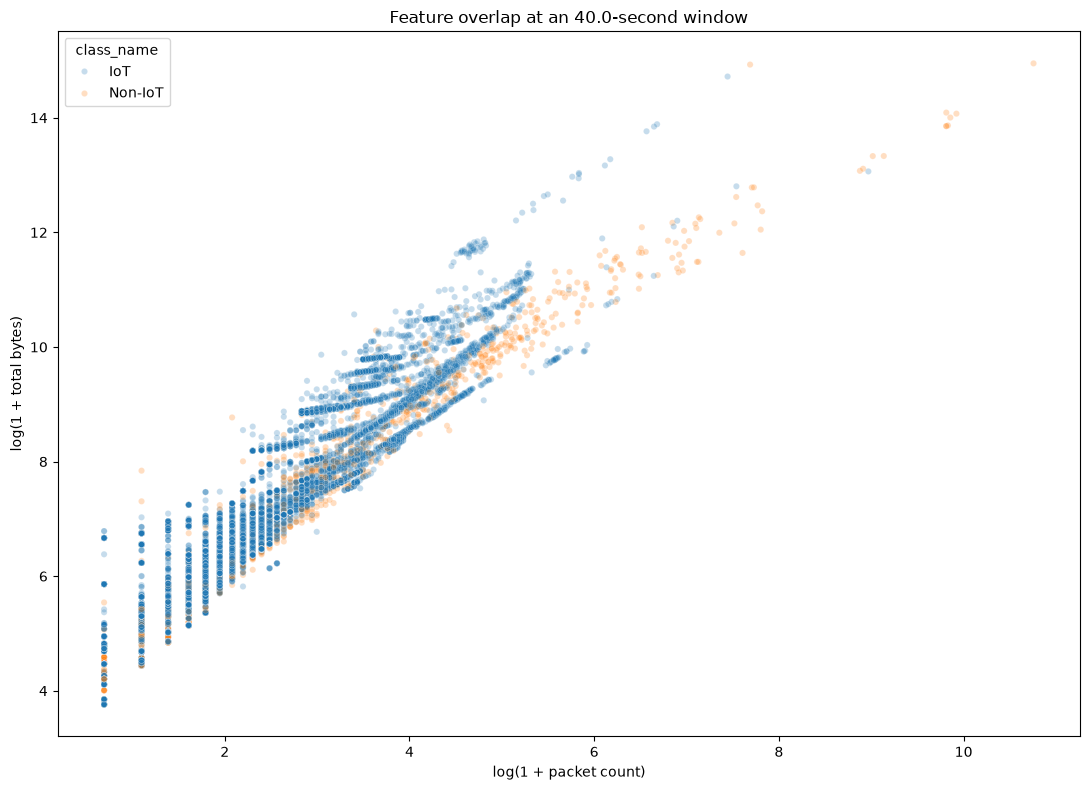

In [64]:
plot_df = data_df_EXAMINING_WINDOW_SIZE.copy()

plot_df["log_packet_count"] = np.log1p(
    plot_df["packet_count"]
)
plot_df["log_total_bytes"] = np.log1p(
    plot_df["total_bytes"]
)
plot_df["class_name"] = plot_df[LABEL_COLUMN].map(
    {0: "Non-IoT", 1: "IoT"}
)

if len(plot_df) > 40_000:
    plot_sample = plot_df.sample(
        40_000,
        random_state=RANDOM_STATE,
    )
else:
    plot_sample = plot_df

plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=plot_sample,
    x="log_packet_count",
    y="log_total_bytes",
    hue="class_name",
    alpha=0.25,
    s=20,
)

target_points = plot_df[
    plot_df["eth.src"].isin(TARGET_DEVICES)
    & (plot_df["packet_count"] > 0)
]

# sns.scatterplot(
#     data=target_points,
#     x="log_packet_count",
#     y="log_total_bytes",
#     color="red",
#     marker="X",
#     s=80,
#     label="Four examined devices",
# )

plt.title(f"Feature overlap at an {EXAMINING_WINDOW_SIZE}-second window")
plt.xlabel("log(1 + packet count)")
plt.ylabel("log(1 + total bytes)")
plt.tight_layout()
plt.show()

# Insight
- The problem: Given data trace for the whole day of a device, can i predict if that device is an IoT or non-IoT?
- Data preprocessing steps:
    - Any devices that only have one trace file is dropped because they can't be splitted into training and validation fold
- Training and validation fold is splitted using Leave-One-Out approach
    - In each fold, for each device, pick one trace file for the validation, the rest will be placed in the training folds

- The reason for the misclassification is that:
    - Vector `(0,0)` get classfied as `0`, and this vector dominate the features belonging to these devices
        - Even though `(0,0)` associated with label 1 more (5000 vs 2000), `RandomUnderSampler` actually remove that dominant. <mark>What happen if we remove it?</mark>
            - Okay, without `RandomUnderSampler`, there is an imbalanced dataset, which make the model predict everything to be IoT. What if we add `classweight` to penalize wrong prediction on non-IoT class heavier?
                - After adding classweight, the same misclassification still happening, what if we drop those device?
                    - After dropping those devices, the accuracy increase significantly. Out of 5 folds, we usually get 3 folds with maximum accuracy, the rest usually get misclassified on `[74:c6:3b:29:d7:1d, e0:76:d0:33:bb:85]`
                - Okay, if we don't drop it, then what is the solution? <mark> can we extend the window so that the number of inactive window get smaller in those devices? Let's try</mark>
                    - I tried up to 11 hours window size. Something interesting appears. The accuracy does increase but we haven't reached 100%.
                    - I thought about increasing the window size more, but it would be irrational. Since we evaluate the device based on the trace of one day worth of trace, if our window size is about 12 hours, then we only have 2 sample for training and validation which is no different than random decision.
    - Nest Protect has a different problem. Its active window are still being predicted as non-IoT. <mark>We might need to add features?</mark>
        - We might need more information to be able to tell it apart. <mark>More features?</mark>
            - We have been only recording outgoing volume, what about incoming? <mark> Try that and it doesn't improve</mark>

# Meeting Note
## Do another sampler method
## We can skip inactive window while training and validating 
- <mark> Trying this first</mark>
- First observation:
    - Optimal window size: 2400, accuracy: 91%
    - The misclassified devices are all false positive, which seems like an imbalanced dataset
    - The window size vs performance plot looks messy, looks pretty much like random -> <mark>might be mixed signal between iot device and non-iot device?</mark>
```bash
mac: 08:21:ef:3b:fc:e3, device_name: Samsung Galaxy Tab, is_iot_device: 0, vendor: nan
mac: b4:ce:f6:a7:a3:c2, device_name: Android Phone, is_iot_device: 0, vendor: nan
mac: 40:f3:08:ff:1e:da, device_name: Android Phone, is_iot_device: 0, vendor: nan
mac: d0:a6:37:df:a1:e1, device_name: IPhone, is_iot_device: 0, vendor: nan
```
- Is it because of camera being in the dataset?
    - Looks like it is, when I drop camera from the dataset, the model reach it peaks at `100 seconds window`
        - It got 100% accuracy in three folds. One fold, it misclassifies `b4:ce:f6:a7:a3:c2`, and `74:6a:89:00:2e:25` for the others.
            - Reason: [Validation detail](./imgs/50-50-decision.png)
                - For `b4:ce:f6:a7:a3:c2`, the model is 50/50 on this decision
                - For `74:6a:89:00:2e:25`, same issue we had initially, this produces too less window for us to vote efficiently
    - Also looking at the scatter plot for this window, the data looks much more separable [Distribution Plots](./imgs/100s-window-distribution-plot.png)
- What if we also drop the gateway?
    - We drop it and got 100% accuracy!! for 120 seconds window
- What if we drop gateway and keep camera?
    - Some devices can not be classified correctly because of following reasons ([40s window dropping gateway performance](./imgs/40s-window-drop-gateway.png)):
        - 50/50 scenario
        - Some IoT devices (blood pressure) has too small number of active windows to be considered for majority voting
- Now that we know the full labels of the dataset? What if we rerun the experiment?
    - For some reason, the list of devices mentioned in the paper cannot be found in the dataset
## Another feature can be last inactive time
## Look into graph model kind of thing

# Additional Analysis

In [65]:
debug_device_list = camera_devices.copy()
for mac in device_dict_1:
    if device_dict_1[mac]["is_iot_device"] == 0 and mac != "14:cc:20:51:33:ea":
        debug_device_list.append(mac)
debug_features = build_feature(raw_df=process_df, device_to_be_include=debug_device_list, window=100)
camera_and_non_iot_ft = label_features(features=debug_features, device_mapping=device_dict_1)

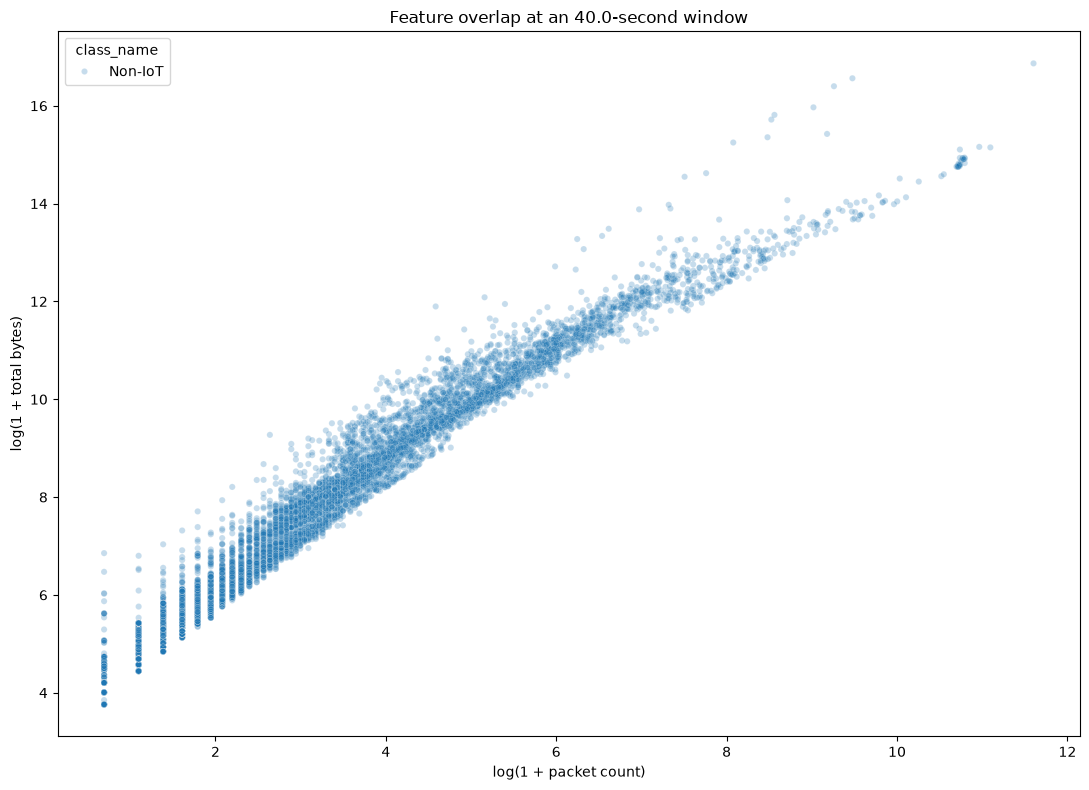

In [66]:
plot_df = camera_and_non_iot_ft.copy()

plot_df["log_packet_count"] = np.log1p(
    plot_df["packet_count"]
)
plot_df["log_total_bytes"] = np.log1p(
    plot_df["total_bytes"]
)
plot_df["class_name"] = plot_df[LABEL_COLUMN].map(
    {0: "Non-IoT", 1: "IoT"}
)

if len(plot_df) > 40_000:
    plot_sample = plot_df.sample(
        40_000,
        random_state=RANDOM_STATE,
    )
else:
    plot_sample = plot_df

plt.figure(figsize=(11, 8))

sns.scatterplot(
    data=plot_sample,
    x="log_packet_count",
    y="log_total_bytes",
    hue="class_name",
    alpha=0.25,
    s=20,
)

target_points = plot_df[
    plot_df["eth.src"].isin(TARGET_DEVICES)
    & (plot_df["packet_count"] > 0)
]

plt.title(f"Feature overlap at an {EXAMINING_WINDOW_SIZE}-second window")
plt.xlabel("log(1 + packet count)")
plt.ylabel("log(1 + total bytes)")
plt.tight_layout()
plt.show()